<a href="https://colab.research.google.com/github/CaioSilvaUSP/cineticamodelos/blob/master/Estudo_Elipse_confian%C3%A7a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gerar os dados para  depois estimar os parâmetros

# Bhandere 2021

In [ ]:
import numpy as np
import pandas as pd

Relação entre $K_{eq}$ e $k_d$ originando $k_{inv}$

Unificando as condições experimentais

==== RESULTADOS ====
Coeficiente angular (a): -2.133757
Coeficiente linear (b): 0.004323
Coeficiente de determinação (R²): 0.814282
Correlação de Pearson: -0.902376

➡ Relação inversa confirmada: conforme x aumenta, y diminui.


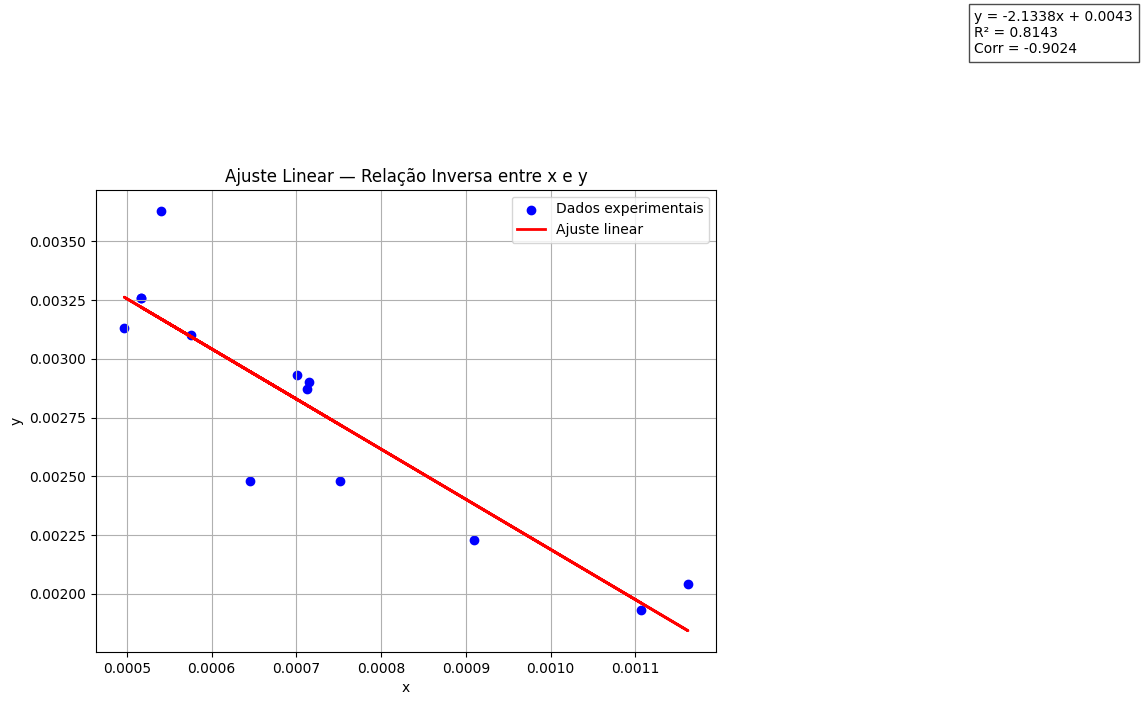

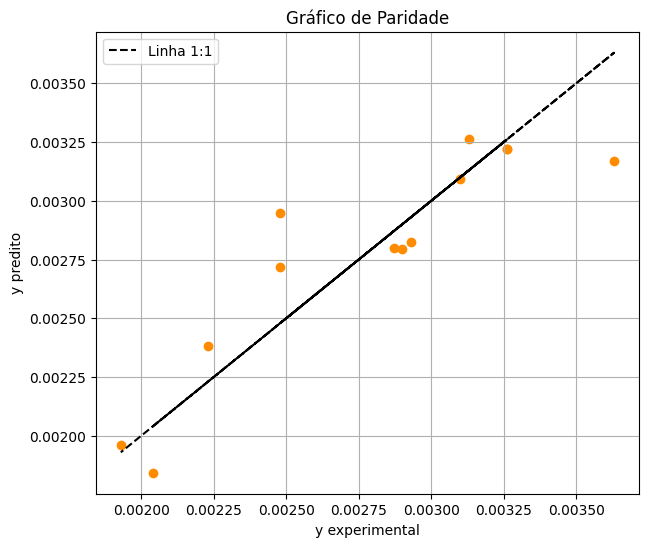

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from sklearn.metrics import r2_score
from io import StringIO

# =========================================================
# === 1. DADOS ============================================
# =========================================================
dados_brutos = """
0.000517 0.00326
0.000576 0.00310
0.000497 0.00313
0.000752 0.00248
0.000540 0.00363
0.000713 0.00287
0.000909 0.00223
0.001162 0.00204
0.000645 0.00248
0.000701 0.00293
0.000517 0.00326
0.000715 0.00290
0.001107 0.00193

"""

# =========================================================
# === 2. LÊ OS DADOS ======================================
# =========================================================
dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])

# =========================================================
# === 3. MODELO: reta y = a*x + b =========================
# =========================================================
def f_reta(x, par):
    b, a = par
    return a * x + b

# =========================================================
# === 4. FUNÇÃO DE RESÍDUOS ===============================
# =========================================================
def f_res(par, f_modelo, X, Y):
    y_pred = f_modelo(X, par)
    return y_pred - Y

# =========================================================
# === 5. AJUSTE POR MÍNIMOS QUADRADOS =====================
# =========================================================
X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()

par_inicial = [0.0, -1.0]  # chute inicial negativo
resp_estimacao = least_squares(f_res, par_inicial, args=(f_reta, X, Y))
b_est, a_est = resp_estimacao.x

# =========================================================
# === 6. AVALIAÇÃO DO AJUSTE ==============================
# =========================================================
y_pred = f_reta(X, [b_est, a_est])
R2 = r2_score(Y, y_pred)
corr = np.corrcoef(X, Y)[0,1]  # correlação de Pearson

print("==== RESULTADOS ====")
print(f"Coeficiente angular (a): {a_est:.6f}")
print(f"Coeficiente linear (b): {b_est:.6f}")
print(f"Coeficiente de determinação (R²): {R2:.6f}")
print(f"Correlação de Pearson: {corr:.6f}")

if a_est < 0:
    print("\n➡ Relação inversa confirmada: conforme x aumenta, y diminui.")
else:
    print("\n➡ Relação direta: conforme x aumenta, y também aumenta.")

# =========================================================
# === 7. GRÁFICO DE AJUSTE LINEAR =========================
# =========================================================
plt.figure(figsize=(8,6))
plt.scatter(dados["x"], dados["y"], color='blue', label='Dados experimentais')
plt.plot(dados["x"], y_pred, color='red', linewidth=2, label='Ajuste linear')

# Adiciona a equação da reta e R² no gráfico
plt.text(
    0.0015, 0.0043,
    f"y = {a_est:.4f}x + {b_est:.4f}\nR² = {R2:.4f}\nCorr = {corr:.4f}",
    fontsize=10,
    bbox=dict(facecolor='white', alpha=0.7)
)

plt.xlabel('x')
plt.ylabel('y')
plt.title('Ajuste Linear — Relação Inversa entre x e y')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 8. GRÁFICO DE PARIDADE ==============================
# =========================================================
plt.figure(figsize=(7,6))
plt.scatter(Y, y_pred, color='darkorange')
plt.plot(Y, Y, 'k--', label='Linha 1:1')
plt.xlabel('y experimental')
plt.ylabel('y predito')
plt.title('Gráfico de Paridade')
plt.legend()
plt.grid(True)
plt.show()


==== AJUSTE REAL ====
a = -2.133757
b = 0.004323
R² = 0.814282


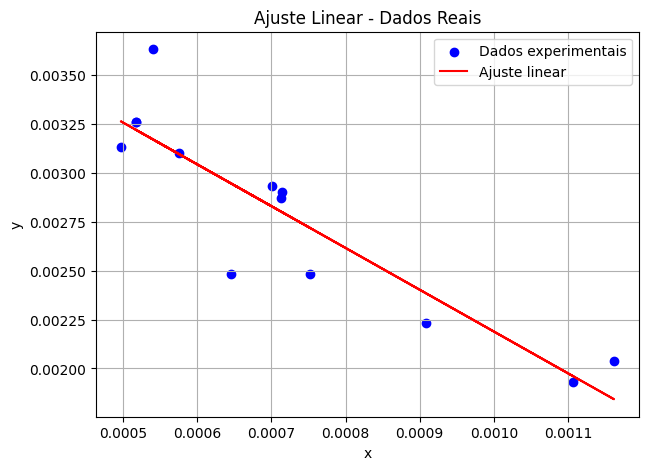

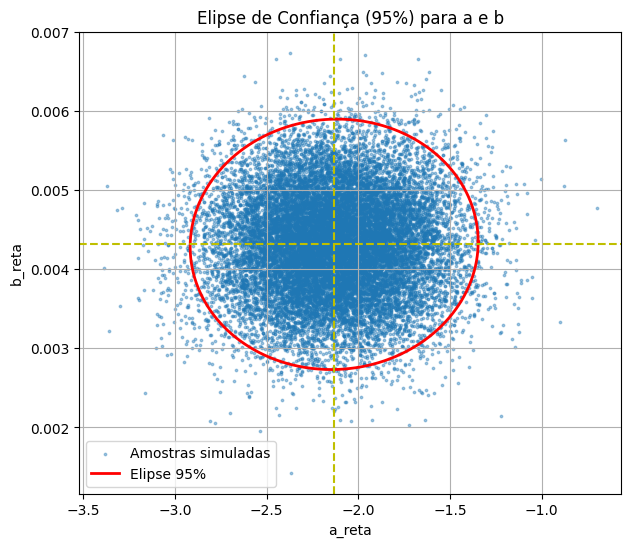

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from sklearn.metrics import r2_score
from scipy.stats import chi2
from scipy.linalg import sqrtm

# =========================================================
# === 1. DADOS REAIS ======================================
# =========================================================
dados_brutos = """
0.000517 0.00326
0.000576 0.00310
0.000497 0.00313
0.000752 0.00248
0.000540 0.00363
0.000713 0.00287
0.000909 0.00223
0.001162 0.00204
0.000645 0.00248
0.000701 0.00293
0.000517 0.00326
0.000715 0.00290
0.001107 0.00193
"""

dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])

# =========================================================
# === 2. AJUSTE LINEAR COM DADOS REAIS ====================
# =========================================================
def f_reta(x, par):
    b, a = par
    return a * x + b

def f_res(par, f_modelo, X, Y):
    return f_modelo(X, par) - Y

X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()

par_inicial = [0.0, -1.0]
resp = least_squares(f_res, par_inicial, args=(f_reta, X, Y))
b_est, a_est = resp.x
y_pred = f_reta(X, [b_est, a_est])
R2 = r2_score(Y, y_pred)

print("==== AJUSTE REAL ====")
print(f"a = {a_est:.6f}")
print(f"b = {b_est:.6f}")
print(f"R² = {R2:.6f}")

plt.figure(figsize=(7,5))
plt.scatter(X, Y, color='blue', label='Dados experimentais')
plt.plot(X, y_pred, color='red', label='Ajuste linear')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Ajuste Linear - Dados Reais')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 3. SIMULAÇÃO DE INCERTEZA EM TORNO DE a E b =========
# =========================================================
# Ruído proporcional à magnitude estimada
np.random.seed(42)
n_amostras = 20000

# Simulamos variação normal em torno dos parâmetros reais
a_sim = np.random.normal(a_est, abs(a_est)*0.15, n_amostras)
b_sim = np.random.normal(b_est, abs(b_est)*0.15, n_amostras)

df_par = pd.DataFrame({"a_reta": a_sim, "b_reta": b_sim})

# =========================================================
# === 4. FUNÇÃO PARA ELIPSE DE CONFIANÇA ==================
# =========================================================
def f_graf_elipse_conf(par1, par2, df_par, conf_inter):
    samples = df_par[[par1, par2]].to_numpy()
    Sigma = np.cov(samples.T)
    n = 2

    # raio estatístico
    r = np.sqrt(chi2.isf(1 - conf_inter, df=n))
    T = np.linspace(0, 2*np.pi, num=2000)
    circle = r * np.vstack([np.cos(T), np.sin(T)])
    x_elipse, y_elipse = sqrtm(Sigma) @ circle

    mean_x, mean_y = df_par[par1].mean(), df_par[par2].mean()
    x_elipse_trnsl = x_elipse + mean_x
    y_elipse_trnsl = y_elipse + mean_y

    fig, ax = plt.subplots(figsize=(7,6))
    ax.scatter(df_par[par1], df_par[par2], s=3, alpha=0.4, label='Amostras simuladas')
    ax.plot(x_elipse_trnsl, y_elipse_trnsl, '-r', linewidth=2, label=f'Elipse {int(conf_inter*100)}%')
    ax.axhline(mean_y, color='y', linestyle='--')
    ax.axvline(mean_x, color='y', linestyle='--')
    ax.set_xlabel(par1)
    ax.set_ylabel(par2)
    ax.set_title(f"Elipse de Confiança ({int(conf_inter*100)}%) para a e b")
    ax.legend()
    ax.grid(True)
    plt.show()

# =========================================================
# === 5. PLOT DA ELIPSE ===================================
# =========================================================
f_graf_elipse_conf('a_reta', 'b_reta', df_par, 0.95)


=== RESULTADOS DO AJUSTE ===
Coef. angular (a): 798.271029
Coef. linear (b): 0.138022
Correlação entre a e b: -0.767501


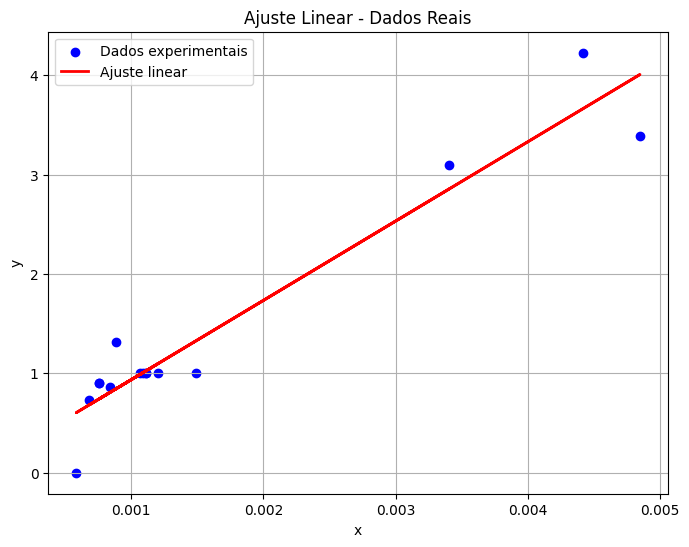

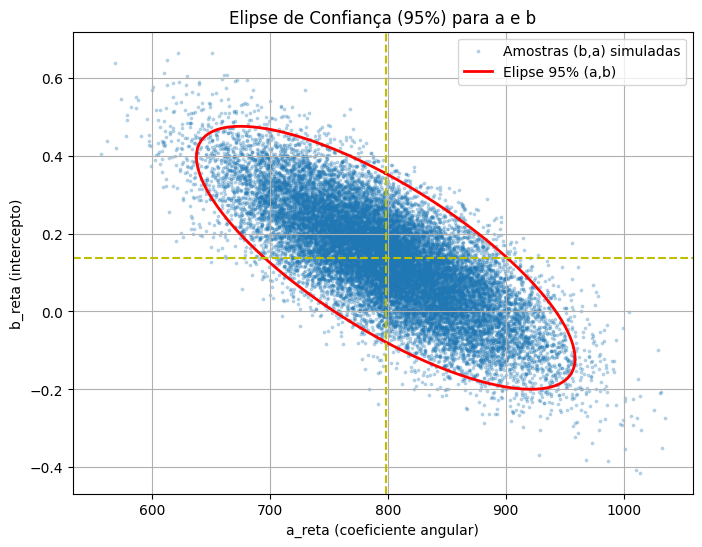

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.linalg import sqrtm
from io import StringIO

# =========================================================
# === 1. NOVOS DADOS EXPERIMENTAIS ========================
# =========================================================
dados_brutos = """
0.000755 0.905
0.000837 0.864
0.000684 0.733
0.001206 1
0.000883 1.312
0.001109 1
0.001492 1
0.004421 4.228
0.004849 3.385
0.000585 0
0.001067 1
0.001090 1
0.000755 0.905
0.001113 1
0.003406 3.098
"""

# =========================================================
# === 2. LÊ OS DADOS ======================================
# =========================================================
dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])
X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()
n = len(X)

# =========================================================
# === 3. AJUSTE LINEAR ANALÍTICO ==========================
# =========================================================
A = np.vstack([np.ones_like(X), X]).T  # matriz [1, x]
beta_hat = np.linalg.lstsq(A, Y, rcond=None)[0]
b_est, a_est = beta_hat[0], beta_hat[1]

# resíduos e sigma²
resid = Y - (a_est * X + b_est)
sigma2_hat = np.sum(resid**2) / (n - 2)

# matriz de covariância dos parâmetros
XtX_inv = np.linalg.inv(A.T @ A)
cov_beta = sigma2_hat * XtX_inv

# correlação entre b e a
corr_ba = cov_beta[0,1] / np.sqrt(cov_beta[0,0]*cov_beta[1,1])

print("=== RESULTADOS DO AJUSTE ===")
print(f"Coef. angular (a): {a_est:.6f}")
print(f"Coef. linear (b): {b_est:.6f}")
print(f"Correlação entre a e b: {corr_ba:.6f}")

# =========================================================
# === 4. GRÁFICO DO AJUSTE REAL ===========================
# =========================================================
y_pred = a_est * X + b_est
plt.figure(figsize=(8,6))
plt.scatter(X, Y, color='blue', label='Dados experimentais')
plt.plot(X, y_pred, color='red', label='Ajuste linear', linewidth=2)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Ajuste Linear - Dados Reais')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 5. ELLIPSE DE CONFIANÇA ENTRE a E b ================
# =========================================================
# amostras multivariadas coerentes com cov_beta
n_amostras = 20000
samples = np.random.multivariate_normal(mean=beta_hat, cov=cov_beta, size=n_amostras)
df_par = pd.DataFrame({"b_reta": samples[:,0], "a_reta": samples[:,1]})

# elipse teórica
r = np.sqrt(chi2.isf(1-0.95, df=2))
T = np.linspace(0, 2*np.pi, 400)
circle = r * np.vstack([np.cos(T), np.sin(T)])
x_el, y_el = sqrtm(cov_beta) @ circle
x_el_tr = x_el + b_est
y_el_tr = y_el + a_est

# gráfico
plt.figure(figsize=(8,6))
plt.scatter(df_par["a_reta"], df_par["b_reta"], s=3, alpha=0.25, label='Amostras (b,a) simuladas')
plt.plot(y_el_tr, x_el_tr, '-r', linewidth=2, label='Elipse 95% (a,b)')
plt.axvline(a_est, color='y', linestyle='--')
plt.axhline(b_est, color='y', linestyle='--')
plt.xlabel('a_reta (coeficiente angular)')
plt.ylabel('b_reta (intercepto)')
plt.title('Elipse de Confiança (95%) para a e b')
plt.legend()
plt.grid(True)
plt.show()


=== ESTATÍSTICAS DOS DADOS ===
Média x: 0.001617
Média y: 1.428667
Correlação entre x e y: 0.958870


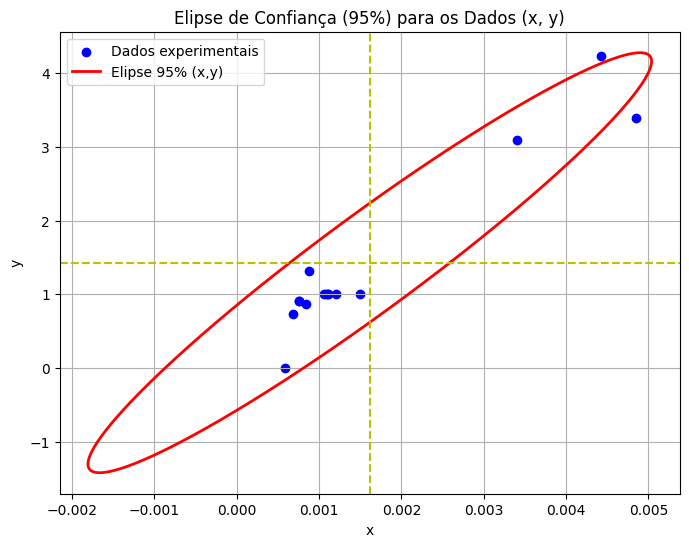

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.linalg import sqrtm
from io import StringIO

# =========================================================
# === 1. NOVOS DADOS EXPERIMENTAIS ========================
# =========================================================
dados_brutos = """
0.000755 0.905
0.000837 0.864
0.000684 0.733
0.001206 1
0.000883 1.312
0.001109 1
0.001492 1
0.004421 4.228
0.004849 3.385
0.000585 0
0.001067 1
0.001090 1
0.000755 0.905
0.001113 1
0.003406 3.098
"""

# =========================================================
# === 2. LÊ OS DADOS ======================================
# =========================================================
dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])
X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()

# =========================================================
# === 3. ESTATÍSTICAS E COVARIÂNCIA =======================
# =========================================================
mean_x, mean_y = np.mean(X), np.mean(Y)
cov_xy = np.cov(X, Y)
corr_xy = np.corrcoef(X, Y)[0,1]

print("=== ESTATÍSTICAS DOS DADOS ===")
print(f"Média x: {mean_x:.6f}")
print(f"Média y: {mean_y:.6f}")
print(f"Correlação entre x e y: {corr_xy:.6f}")

# =========================================================
# === 4. ELIPSE DE CONFIANÇA PARA (x, y) ==================
# =========================================================
# Nível de confiança 95% (χ² para 2 graus de liberdade)
r = np.sqrt(chi2.isf(1-0.95, df=2))
T = np.linspace(0, 2*np.pi, 400)
circle = r * np.vstack([np.cos(T), np.sin(T)])

# Matriz raiz da covariância
transform = sqrtm(cov_xy)
ellipse_points = transform @ circle

# Translação para o centro (médias)
x_el = ellipse_points[0,:] + mean_x
y_el = ellipse_points[1,:] + mean_y

# =========================================================
# === 5. GRÁFICO: DISPERSÃO E ELIPSE ======================
# =========================================================
plt.figure(figsize=(8,6))
plt.scatter(X, Y, color='blue', label='Dados experimentais')
plt.plot(x_el, y_el, color='red', linewidth=2, label='Elipse 95% (x,y)')
plt.axvline(mean_x, color='y', linestyle='--')
plt.axhline(mean_y, color='y', linestyle='--')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Elipse de Confiança (95%) para os Dados (x, y)')
plt.legend()
plt.grid(True)
plt.show()


relação de kd e kw

=== RESULTADOS DO AJUSTE ===
Coeficiente angular (a): 798.271029
Intercepto (b): 0.138022
Desvio padrão residual: 0.342778

=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===
Média x: 0.001625
Média y: 1.431533
Correlação x–y: 0.954705


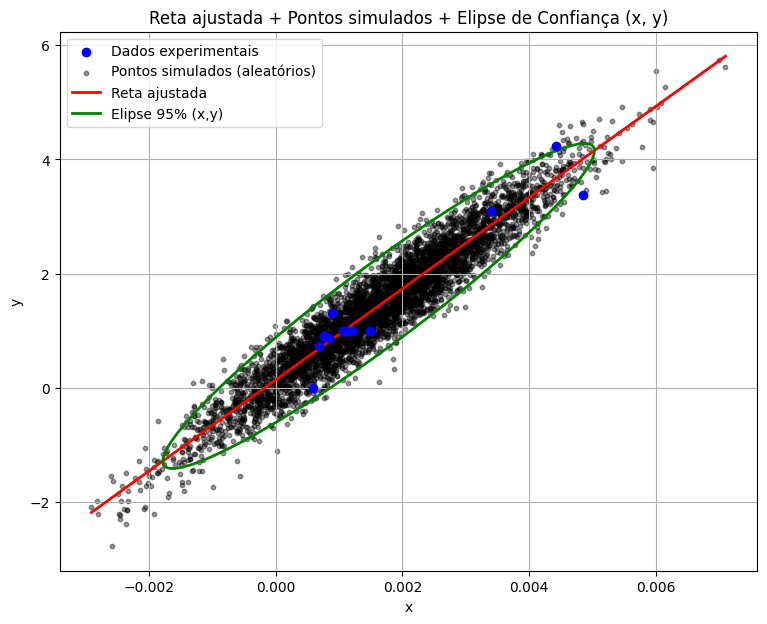

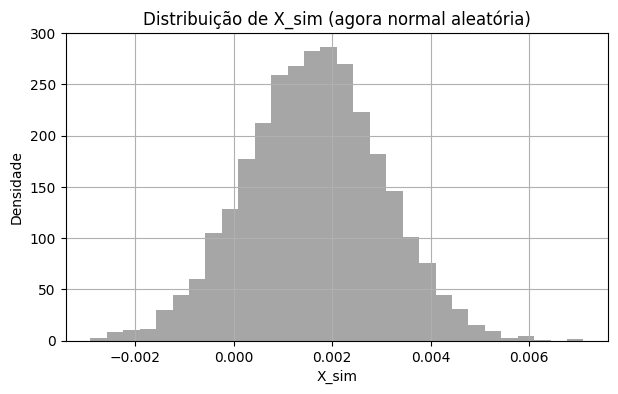

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.linalg import sqrtm
from io import StringIO

# =========================================================
# === 1. NOVOS DADOS EXPERIMENTAIS ========================
# =========================================================
dados_brutos = """
0.000755 0.905
0.000837 0.864
0.000684 0.733
0.001206 1
0.000883 1.312
0.001109 1
0.001492 1
0.004421 4.228
0.004849 3.385
0.000585 0
0.001067 1
0.001090 1
0.000755 0.905
0.001113 1
0.003406 3.098
"""

# =========================================================
# === 2. LÊ OS DADOS ======================================
# =========================================================
dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])
X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()
n = len(X)

# =========================================================
# === 3. AJUSTE LINEAR ====================================
# =========================================================
A = np.vstack([np.ones_like(X), X]).T
beta_hat = np.linalg.lstsq(A, Y, rcond=None)[0]
b_est, a_est = beta_hat
Y_pred = a_est * X + b_est

# resíduos e variância
resid = Y - Y_pred
sigma2_hat = np.var(resid, ddof=2)
sigma_hat = np.sqrt(sigma2_hat)

print("=== RESULTADOS DO AJUSTE ===")
print(f"Coeficiente angular (a): {a_est:.6f}")
print(f"Intercepto (b): {b_est:.6f}")
print(f"Desvio padrão residual: {sigma_hat:.6f}")

# =========================================================
# === 4. GERA NOVOS PONTOS A PARTIR DO MODELO (ALEATÓRIO) =
# =========================================================
np.random.seed(42)
n_sintetico = 5000

# X_sim aleatório com distribuição normal baseada nos dados reais
media_x = np.mean(X)
desvio_x = np.std(X, ddof=1)
X_sim = np.random.normal(media_x, desvio_x, n_sintetico)

# Gera Y_sim conforme o modelo linear + ruído experimental
Y_sim = a_est * X_sim + b_est + np.random.normal(0, sigma_hat, n_sintetico)

# =========================================================
# === 5. COVARIÂNCIA E ELIPSE NO ESPAÇO (x, y) ============
# =========================================================
mean_x, mean_y = np.mean(X_sim), np.mean(Y_sim)
cov_xy = np.cov(X_sim, Y_sim)
corr_xy = np.corrcoef(X_sim, Y_sim)[0, 1]

print("\n=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===")
print(f"Média x: {mean_x:.6f}")
print(f"Média y: {mean_y:.6f}")
print(f"Correlação x–y: {corr_xy:.6f}")

# elipse 85%
r = np.sqrt(chi2.isf(1 - 0.95, df=2))
T = np.linspace(0, 2*np.pi, 400)
circle = r * np.vstack([np.cos(T), np.sin(T)])
transform = sqrtm(cov_xy)
ellipse_points = transform @ circle
x_el = ellipse_points[0, :] + mean_x
y_el = ellipse_points[1, :] + mean_y

# =========================================================
# === 6. GRÁFICO FINAL ====================================
# =========================================================
plt.figure(figsize=(9,7))
plt.scatter(X, Y, color='blue', label='Dados experimentais', zorder=3)
plt.scatter(X_sim, Y_sim, color='black', s=10, alpha=0.4, label='Pontos simulados (aleatórios)', zorder=1)
plt.plot(np.sort(X_sim), a_est * np.sort(X_sim) + b_est, color='red', linewidth=2, label='Reta ajustada')
plt.plot(x_el, y_el, color='green', linewidth=2, label='Elipse 95% (x,y)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Reta ajustada + Pontos simulados + Elipse de Confiança (x, y)')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 7. HISTOGRAMA PARA VERIFICAR X SIMULADO ============
# =========================================================
plt.figure(figsize=(7,4))
plt.hist(X_sim, bins=30, density=True, color='gray', alpha=0.7)
plt.title('Distribuição de X_sim (agora normal aleatória)')
plt.xlabel('X_sim')
plt.ylabel('Densidade')
plt.grid(True)
plt.show()


Adicionando um erro de 5% para melhor confiabilidade do resultado em comparação a ensaios experimentais

=== RESULTADOS DO AJUSTE ===
Coeficiente angular (a): 798.271029
Intercepto (b): 0.138022
Desvio padrão residual: 0.342778
R² (dados experimentais): 0.919432

=== CORRELAÇÃO E QUALIDADE DO AJUSTE ===
Média x: 0.001625
Média y: 1.431905
Correlação x–y (simulados): 0.953810
R² (pontos simulados com erro): 0.909746


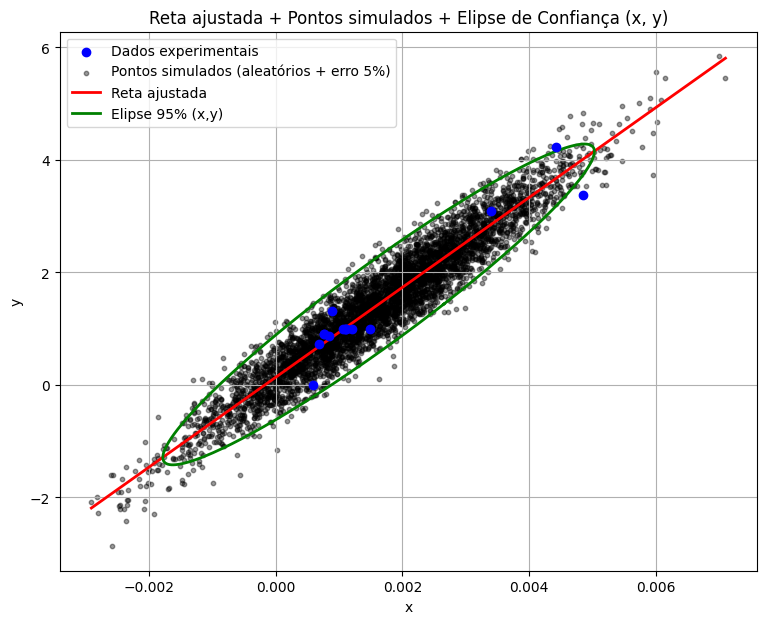

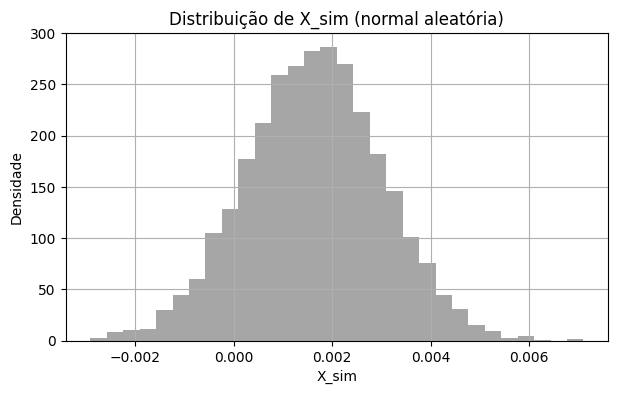

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.linalg import sqrtm
from io import StringIO

# =========================================================
# === 1. NOVOS DADOS EXPERIMENTAIS ========================
# =========================================================
dados_brutos = """
0.000755 0.905
0.000837 0.864
0.000684 0.733
0.001206 1
0.000883 1.312
0.001109 1
0.001492 1
0.004421 4.228
0.004849 3.385
0.000585 0
0.001067 1
0.001090 1
0.000755 0.905
0.001113 1
0.003406 3.098
"""

# =========================================================
# === 2. LÊ OS DADOS ======================================
# =========================================================
dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])
X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()
n = len(X)

# =========================================================
# === 3. AJUSTE LINEAR ====================================
# =========================================================
A = np.vstack([np.ones_like(X), X]).T
beta_hat = np.linalg.lstsq(A, Y, rcond=None)[0]
b_est, a_est = beta_hat
Y_pred = a_est * X + b_est

# resíduos e variância
resid = Y - Y_pred
sigma2_hat = np.var(resid, ddof=2)
sigma_hat = np.sqrt(sigma2_hat)

# R² dos dados experimentais
SS_tot = np.sum((Y - np.mean(Y))**2)
SS_res = np.sum((Y - Y_pred)**2)
R2_exp = 1 - SS_res / SS_tot

print("=== RESULTADOS DO AJUSTE ===")
print(f"Coeficiente angular (a): {a_est:.6f}")
print(f"Intercepto (b): {b_est:.6f}")
print(f"Desvio padrão residual: {sigma_hat:.6f}")
print(f"R² (dados experimentais): {R2_exp:.6f}")

# =========================================================
# === 4. GERA NOVOS PONTOS A PARTIR DO MODELO (ALEATÓRIO) =
# =========================================================
np.random.seed(42)
n_sintetico = 5000

# X_sim aleatório com distribuição normal baseada nos dados reais
media_x = np.mean(X)
desvio_x = np.std(X, ddof=1)
X_sim = np.random.normal(media_x, desvio_x, n_sintetico)

# Gera Y_sim conforme o modelo linear + ruído experimental
Y_sim = a_est * X_sim + b_est + np.random.normal(0, sigma_hat, n_sintetico)

# =========================================================
# === 5. ADICIONA ERRO EXPERIMENTAL REALISTA (±5%) ========
# =========================================================
erro_perc = 0.05  # erro típico de medições cinéticas (~5%)
Y_sim_erro = Y_sim * (1 + np.random.uniform(-erro_perc, erro_perc, n_sintetico))

# R² dos pontos simulados com erro
Y_pred_sim = a_est * X_sim + b_est
SS_tot_sim = np.sum((Y_sim_erro - np.mean(Y_sim_erro))**2)
SS_res_sim = np.sum((Y_sim_erro - Y_pred_sim)**2)
R2_sim = 1 - SS_res_sim / SS_tot_sim

# =========================================================
# === 6. COVARIÂNCIA E ELIPSE NO ESPAÇO (x, y) ============
# =========================================================
mean_x, mean_y = np.mean(X_sim), np.mean(Y_sim_erro)
cov_xy = np.cov(X_sim, Y_sim_erro)
corr_xy = np.corrcoef(X_sim, Y_sim_erro)[0, 1]

print("\n=== CORRELAÇÃO E QUALIDADE DO AJUSTE ===")
print(f"Média x: {mean_x:.6f}")
print(f"Média y: {mean_y:.6f}")
print(f"Correlação x–y (simulados): {corr_xy:.6f}")
print(f"R² (pontos simulados com erro): {R2_sim:.6f}")

# elipse 95%
r = np.sqrt(chi2.isf(1 - 0.95, df=2))
T = np.linspace(0, 2*np.pi, 400)
circle = r * np.vstack([np.cos(T), np.sin(T)])
transform = sqrtm(cov_xy)
ellipse_points = transform @ circle
x_el = ellipse_points[0, :] + mean_x
y_el = ellipse_points[1, :] + mean_y

# =========================================================
# === 7. GRÁFICO FINAL ====================================
# =========================================================
plt.figure(figsize=(9,7))
plt.scatter(X, Y, color='blue', label='Dados experimentais', zorder=3)
plt.scatter(X_sim, Y_sim_erro, color='black', s=10, alpha=0.4, label='Pontos simulados (aleatórios + erro 5%)', zorder=1)
plt.plot(np.sort(X_sim), a_est * np.sort(X_sim) + b_est, color='red', linewidth=2, label='Reta ajustada')
plt.plot(x_el, y_el, color='green', linewidth=2, label='Elipse 95% (x,y)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Reta ajustada + Pontos simulados + Elipse de Confiança (x, y)')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 8. HISTOGRAMA DE X SIMULADO =========================
# =========================================================
plt.figure(figsize=(7,4))
plt.hist(X_sim, bins=30, density=True, color='gray', alpha=0.7)
plt.title('Distribuição de X_sim (normal aleatória)')
plt.xlabel('X_sim')
plt.ylabel('Densidade')
plt.grid(True)
plt.show()


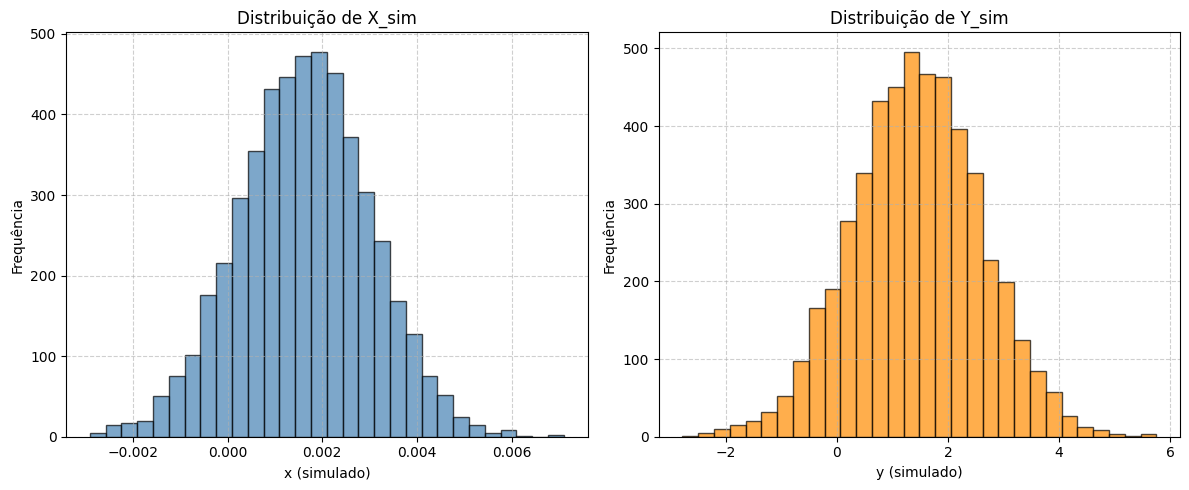

In [ ]:
# =========================================================
# === 7. HISTOGRAMAS SEPARADOS (APENAS SIMULADOS) ========
# =========================================================

plt.figure(figsize=(12, 5))

# --- Histograma de X_sim ---
plt.subplot(1, 2, 1)
plt.hist(X_sim, bins=30, color='steelblue', alpha=0.7, edgecolor='black')
plt.xlabel('x (simulado)')
plt.ylabel('Frequência')
plt.title('Distribuição de X_sim')
plt.grid(True, linestyle='--', alpha=0.6)

# --- Histograma de Y_sim ---
plt.subplot(1, 2, 2)
plt.hist(Y_sim, bins=30, color='darkorange', alpha=0.7, edgecolor='black')
plt.xlabel('y (simulado)')
plt.ylabel('Frequência')
plt.title('Distribuição de Y_sim')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


Gerando com barra de erros

Relação de kd e kinv

=== RESULTADOS DO AJUSTE ===
Coeficiente angular (a): -2.133757
Intercepto (b): 0.004323
Desvio padrão residual: 0.000233

=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===
Média x: 0.000721
Média y: 0.002783
Correlação x–y: -0.892515


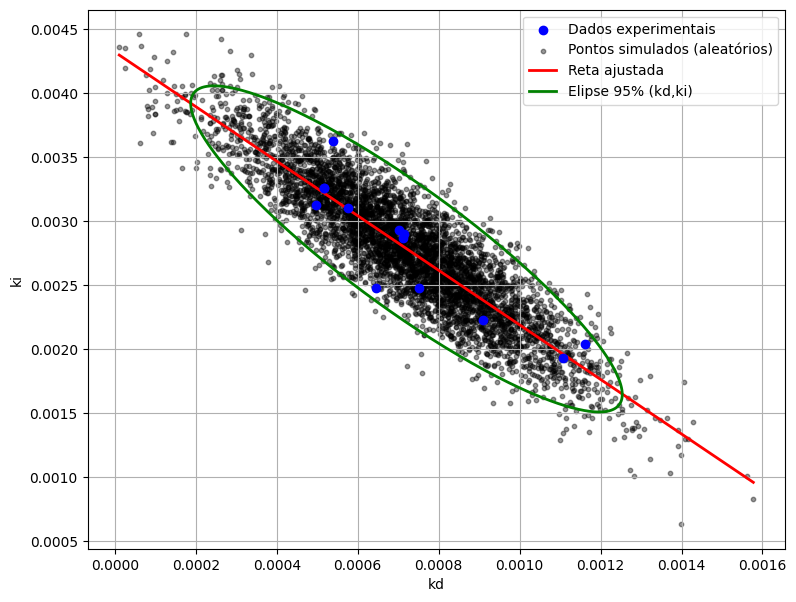

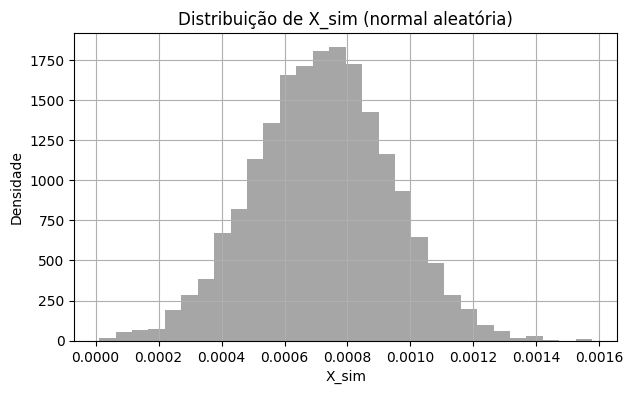

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.linalg import sqrtm
from io import StringIO

# =========================================================
# === 1. NOVOS DADOS EXPERIMENTAIS ========================
# =========================================================
dados_brutos = """
0.000517 0.00326
0.000576 0.00310
0.000497 0.00313
0.000752 0.00248
0.000540 0.00363
0.000713 0.00287
0.000909 0.00223
0.001162 0.00204
0.000645 0.00248
0.000701 0.00293
0.000517 0.00326
0.000715 0.00290
0.001107 0.00193
"""

# =========================================================
# === 2. LÊ OS DADOS ======================================
# =========================================================
dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])
X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()
n = len(X)

# =========================================================
# === 3. AJUSTE LINEAR ====================================
# =========================================================
A = np.vstack([np.ones_like(X), X]).T
beta_hat = np.linalg.lstsq(A, Y, rcond=None)[0]
b_est, a_est = beta_hat
Y_pred = a_est * X + b_est

# resíduos e variância
resid = Y - Y_pred
sigma2_hat = np.var(resid, ddof=2)
sigma_hat = np.sqrt(sigma2_hat)

print("=== RESULTADOS DO AJUSTE ===")
print(f"Coeficiente angular (a): {a_est:.6f}")
print(f"Intercepto (b): {b_est:.6f}")
print(f"Desvio padrão residual: {sigma_hat:.6f}")

# =========================================================
# === 4. GERA NOVOS PONTOS A PARTIR DO MODELO =============
# =========================================================
np.random.seed(42)
n_sintetico = 5000

# X aleatório com distribuição normal baseada em X experimental
media_x = np.mean(X)
desvio_x = np.std(X, ddof=1)
X_sim = np.random.normal(media_x, desvio_x, n_sintetico)

# Y gerado conforme o modelo linear + ruído experimental
Y_sim = a_est * X_sim + b_est + np.random.normal(0, sigma_hat, n_sintetico)

# =========================================================
# === 5. COVARIÂNCIA E ELIPSE NO ESPAÇO (x, y) ============
# =========================================================
mean_x, mean_y = np.mean(X_sim), np.mean(Y_sim)
cov_xy = np.cov(X_sim, Y_sim)
corr_xy = np.corrcoef(X_sim, Y_sim)[0, 1]

print("\n=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===")
print(f"Média x: {mean_x:.6f}")
print(f"Média y: {mean_y:.6f}")
print(f"Correlação x–y: {corr_xy:.6f}")

# elipse 85%
r = np.sqrt(chi2.isf(1 - 0.95, df=2))
T = np.linspace(0, 2 * np.pi, 400)
circle = r * np.vstack([np.cos(T), np.sin(T)])
transform = sqrtm(cov_xy)
ellipse_points = transform @ circle
x_el = ellipse_points[0, :] + mean_x
y_el = ellipse_points[1, :] + mean_y

# =========================================================
# === 6. GRÁFICO FINAL ====================================
# =========================================================
plt.figure(figsize=(9,7))
plt.scatter(X, Y, color='blue', label='Dados experimentais', zorder=3)
plt.scatter(X_sim, Y_sim, color='black', s=10, alpha=0.4, label='Pontos simulados (aleatórios)', zorder=1)
plt.plot(np.sort(X_sim), a_est * np.sort(X_sim) + b_est, color='red', linewidth=2, label='Reta ajustada')
plt.plot(x_el, y_el, color='green', linewidth=2, label='Elipse 95% (kd,ki)')
plt.xlabel('kd')
plt.ylabel('ki')
#plt.title('Reta ajustada + Pontos simulados + Elipse de Confiança (kd, KW)')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 7. VERIFICAÇÃO DA DISTRIBUIÇÃO DE X =================
# =========================================================
plt.figure(figsize=(7,4))
plt.hist(X_sim, bins=30, density=True, color='gray', alpha=0.7)
plt.title('Distribuição de X_sim (normal aleatória)')
plt.xlabel('X_sim')
plt.ylabel('Densidade')
plt.grid(True)
plt.show()


=== LINEAR FIT RESULTS ===
Slope (a): -2.133757
Intercept (b): 0.004323
Residual standard deviation: 0.000233

=== SYNTHETIC POINTS STATISTICS ===
Mean x: 0.000721
Mean y: 0.002783
x–y correlation: -0.892515


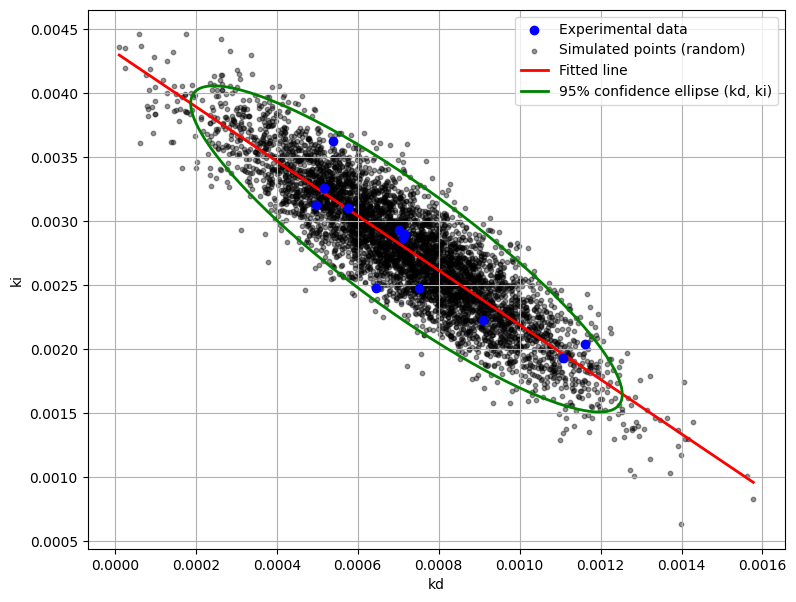

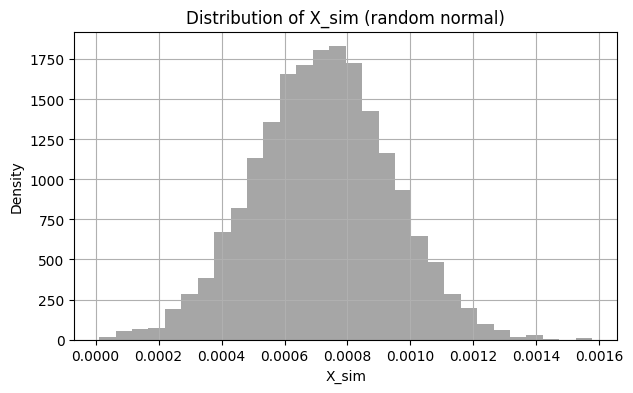

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.linalg import sqrtm
from io import StringIO

# =========================================================
# === 1. NEW EXPERIMENTAL DATA ===========================
# =========================================================
raw_data = """
0.000517 0.00326
0.000576 0.00310
0.000497 0.00313
0.000752 0.00248
0.000540 0.00363
0.000713 0.00287
0.000909 0.00223
0.001162 0.00204
0.000645 0.00248
0.000701 0.00293
0.000517 0.00326
0.000715 0.00290
0.001107 0.00193
"""

# =========================================================
# === 2. READ DATA =======================================
# =========================================================
data = pd.read_csv(StringIO(raw_data), sep=r"\s+", header=None, names=["x", "y"])
X = data["x"].to_numpy()
Y = data["y"].to_numpy()
n = len(X)

# =========================================================
# === 3. LINEAR FIT ======================================
# =========================================================
A = np.vstack([np.ones_like(X), X]).T
beta_hat = np.linalg.lstsq(A, Y, rcond=None)[0]
b_est, a_est = beta_hat
Y_pred = a_est * X + b_est

# residuals and standard deviation
resid = Y - Y_pred
sigma2_hat = np.var(resid, ddof=2)
sigma_hat = np.sqrt(sigma2_hat)

print("=== LINEAR FIT RESULTS ===")
print(f"Slope (a): {a_est:.6f}")
print(f"Intercept (b): {b_est:.6f}")
print(f"Residual standard deviation: {sigma_hat:.6f}")

# =========================================================
# === 4. GENERATE NEW POINTS FROM THE MODEL ==============
# =========================================================
np.random.seed(42)
n_synthetic = 5000

# Random X from normal distribution based on experimental X
mean_x = np.mean(X)
std_x = np.std(X, ddof=1)
X_sim = np.random.normal(mean_x, std_x, n_synthetic)

# Y generated from linear model + experimental noise
Y_sim = a_est * X_sim + b_est + np.random.normal(0, sigma_hat, n_synthetic)

# =========================================================
# === 5. COVARIANCE AND ELLIPSE IN (x, y) SPACE ==========
# =========================================================
mean_x, mean_y = np.mean(X_sim), np.mean(Y_sim)
cov_xy = np.cov(X_sim, Y_sim)
corr_xy = np.corrcoef(X_sim, Y_sim)[0, 1]

print("\n=== SYNTHETIC POINTS STATISTICS ===")
print(f"Mean x: {mean_x:.6f}")
print(f"Mean y: {mean_y:.6f}")
print(f"x–y correlation: {corr_xy:.6f}")

# 95% confidence ellipse
r = np.sqrt(chi2.isf(1 - 0.95, df=2))
T = np.linspace(0, 2 * np.pi, 400)
circle = r * np.vstack([np.cos(T), np.sin(T)])
transform = sqrtm(cov_xy)
ellipse_points = transform @ circle
x_ellipse = ellipse_points[0, :] + mean_x
y_ellipse = ellipse_points[1, :] + mean_y

# =========================================================
# === 6. FINAL PLOT ======================================
# =========================================================
plt.figure(figsize=(9,7))
plt.scatter(X, Y, color='blue', label='Experimental data', zorder=3)
plt.scatter(X_sim, Y_sim, color='black', s=10, alpha=0.4, label='Simulated points (random)', zorder=1)
plt.plot(np.sort(X_sim), a_est * np.sort(X_sim) + b_est, color='red', linewidth=2, label='Fitted line')
plt.plot(x_ellipse, y_ellipse, color='green', linewidth=2, label='95% confidence ellipse (kd, ki)')
plt.xlabel('kd')
plt.ylabel('ki')
#plt.title('Fitted line + Simulated points + Confidence ellipse (kd, KW)')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 7. VERIFY X DISTRIBUTION ===========================
# =========================================================
plt.figure(figsize=(7,4))
plt.hist(X_sim, bins=30, density=True, color='gray', alpha=0.7)
plt.title('Distribution of X_sim (random normal)')
plt.xlabel('X_sim')
plt.ylabel('Density')
plt.grid(True)
plt.show()


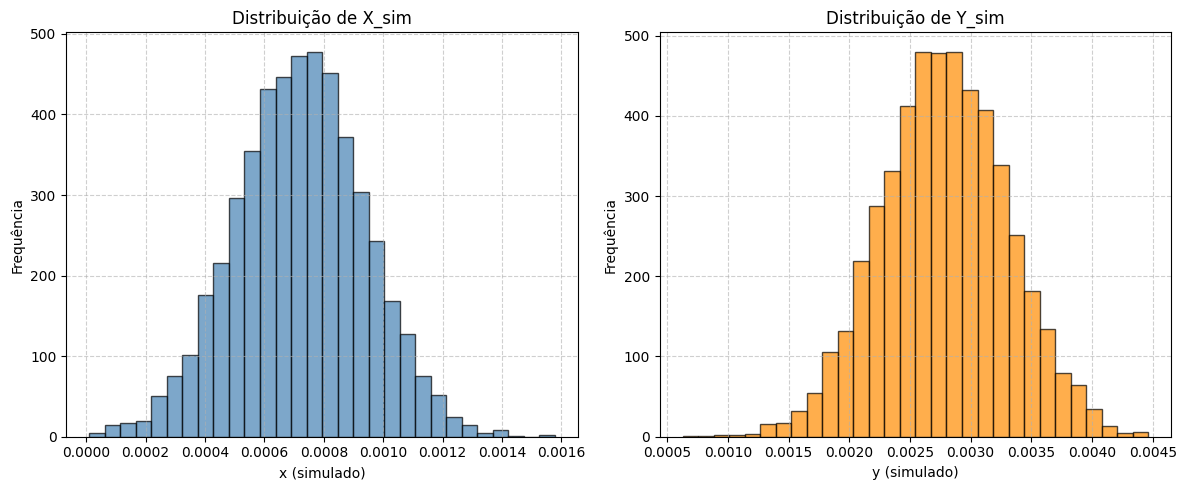

In [ ]:
# =========================================================
# === 7. HISTOGRAMAS SEPARADOS (APENAS SIMULADOS) ========
# =========================================================

plt.figure(figsize=(12, 5))

# --- Histograma de X_sim ---
plt.subplot(1, 2, 1)
plt.hist(X_sim, bins=30, color='steelblue', alpha=0.7, edgecolor='black')
plt.xlabel('x (simulado)')
plt.ylabel('Frequência')
plt.title('Distribuição de X_sim')
plt.grid(True, linestyle='--', alpha=0.6)

# --- Histograma de Y_sim ---
plt.subplot(1, 2, 2)
plt.hist(Y_sim, bins=30, color='darkorange', alpha=0.7, edgecolor='black')
plt.xlabel('y (simulado)')
plt.ylabel('Frequência')
plt.title('Distribuição de Y_sim')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


Matriz de correlação

Matriz de correlação:

           kd1        kW       kd2      kinv
kd1   1.000000  0.958870  0.376722 -0.487067
kW    0.958870  1.000000  0.422860 -0.438058
kd2   0.376722  0.422860  1.000000 -0.902376
kinv -0.487067 -0.438058 -0.902376  1.000000


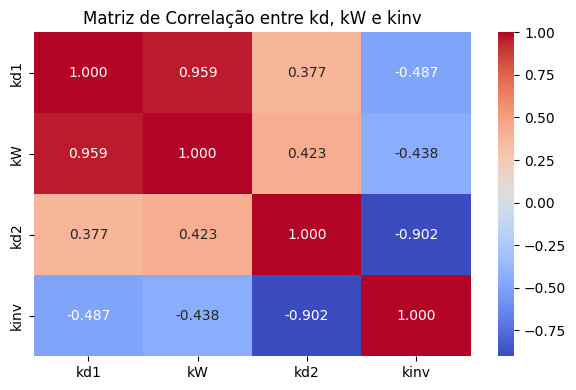

In [ ]:
import pandas as pd
import io
import matplotlib.pyplot as plt
import seaborn as sns

# === DADOS BRUTOS ===
dados1 = """
0.000755 0.905
0.000837 0.864
0.000684 0.733
0.001206 1
0.000883 1.312
0.001109 1
0.001492 1
0.004421 4.228
0.004849 3.385
0.000585 0
0.001067 1
0.001090 1
0.000755 0.905
0.001113 1
0.003406 3.098
"""

dados2 = """
0.000517 0.00326
0.000576 0.00310
0.000497 0.00313
0.000752 0.00248
0.000540 0.00363
0.000713 0.00287
0.000909 0.00223
0.001162 0.00204
0.000645 0.00248
0.000701 0.00293
0.000517 0.00326
0.000715 0.00290
0.001107 0.00193
"""

# === CRIAÇÃO DOS DATAFRAMES ===
df1 = pd.read_csv(io.StringIO(dados1), sep=" ", header=None, names=["kd1", "kW"])
df2 = pd.read_csv(io.StringIO(dados2), sep=" ", header=None, names=["kd2", "kinv"])

# === COMBINAÇÃO DOS DADOS ===
df = pd.concat([df1.reset_index(drop=True), df2.reset_index(drop=True)], axis=1)

# === MATRIZ DE CORRELAÇÃO ===
corr = df.corr()

print("Matriz de correlação:\n")
print(corr)

# === HEATMAP (visualização gráfica) ===
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Matriz de Correlação entre kd, kW e kinv")
plt.tight_layout()
plt.show()


==== AJUSTE REAL ====
a = -1.368975
b = 0.005800
R² = 0.757177


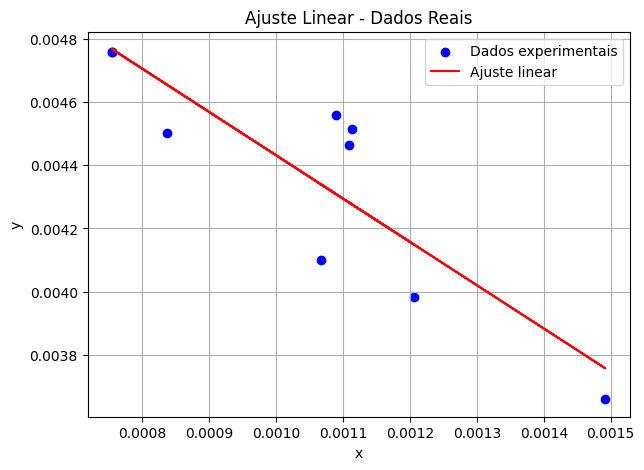

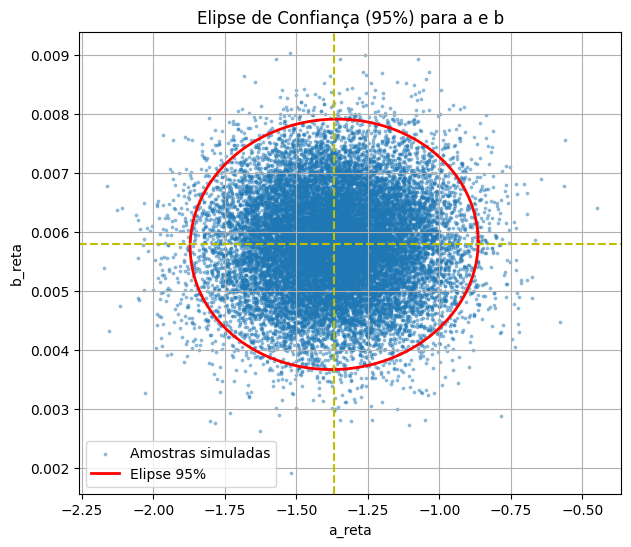

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from sklearn.metrics import r2_score
from scipy.stats import chi2
from scipy.linalg import sqrtm

# =========================================================
# === 1. DADOS REAIS ======================================
# =========================================================
dados_brutos = """
0.000755 0.00475887325
0.000837 0.004501185796
0.001206 0.003983826852
0.001109 0.004464681111
0.001492 0.003660199986
0.001067 0.004101322263
0.00109 0.004558266353
0.000755 0.00475887325
0.001113 0.004513839603
"""

dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])

# =========================================================
# === 2. AJUSTE LINEAR COM DADOS REAIS ====================
# =========================================================
def f_reta(x, par):
    b, a = par
    return a * x + b

def f_res(par, f_modelo, X, Y):
    return f_modelo(X, par) - Y

X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()

par_inicial = [0.0, -1.0]
resp = least_squares(f_res, par_inicial, args=(f_reta, X, Y))
b_est, a_est = resp.x
y_pred = f_reta(X, [b_est, a_est])
R2 = r2_score(Y, y_pred)

print("==== AJUSTE REAL ====")
print(f"a = {a_est:.6f}")
print(f"b = {b_est:.6f}")
print(f"R² = {R2:.6f}")

plt.figure(figsize=(7,5))
plt.scatter(X, Y, color='blue', label='Dados experimentais')
plt.plot(X, y_pred, color='red', label='Ajuste linear')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Ajuste Linear - Dados Reais')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 3. SIMULAÇÃO DE INCERTEZA EM TORNO DE a E b =========
# =========================================================
# Ruído proporcional à magnitude estimada
np.random.seed(42)
n_amostras = 20000

# Simulamos variação normal em torno dos parâmetros reais
a_sim = np.random.normal(a_est, abs(a_est)*0.15, n_amostras)
b_sim = np.random.normal(b_est, abs(b_est)*0.15, n_amostras)

df_par = pd.DataFrame({"a_reta": a_sim, "b_reta": b_sim})

# =========================================================
# === 4. FUNÇÃO PARA ELIPSE DE CONFIANÇA ==================
# =========================================================
def f_graf_elipse_conf(par1, par2, df_par, conf_inter):
    samples = df_par[[par1, par2]].to_numpy()
    Sigma = np.cov(samples.T)
    n = 2

    # raio estatístico
    r = np.sqrt(chi2.isf(1 - conf_inter, df=n))
    T = np.linspace(0, 2*np.pi, num=2000)
    circle = r * np.vstack([np.cos(T), np.sin(T)])
    x_elipse, y_elipse = sqrtm(Sigma) @ circle

    mean_x, mean_y = df_par[par1].mean(), df_par[par2].mean()
    x_elipse_trnsl = x_elipse + mean_x
    y_elipse_trnsl = y_elipse + mean_y

    fig, ax = plt.subplots(figsize=(7,6))
    ax.scatter(df_par[par1], df_par[par2], s=3, alpha=0.4, label='Amostras simuladas')
    ax.plot(x_elipse_trnsl, y_elipse_trnsl, '-r', linewidth=2, label=f'Elipse {int(conf_inter*100)}%')
    ax.axhline(mean_y, color='y', linestyle='--')
    ax.axvline(mean_x, color='y', linestyle='--')
    ax.set_xlabel(par1)
    ax.set_ylabel(par2)
    ax.set_title(f"Elipse de Confiança ({int(conf_inter*100)}%) para a e b")
    ax.legend()
    ax.grid(True)
    plt.show()

# =========================================================
# === 5. PLOT DA ELIPSE ===================================
# =========================================================
f_graf_elipse_conf('a_reta', 'b_reta', df_par, 0.95)


=== RESULTADOS DO AJUSTE ===
Coeficiente angular (a): -1.368975
Intercepto (b): 0.005800
Desvio padrão residual: 0.000196

=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===
Média x: 0.001048
Média y: 0.004363
Correlação x–y: -0.852489


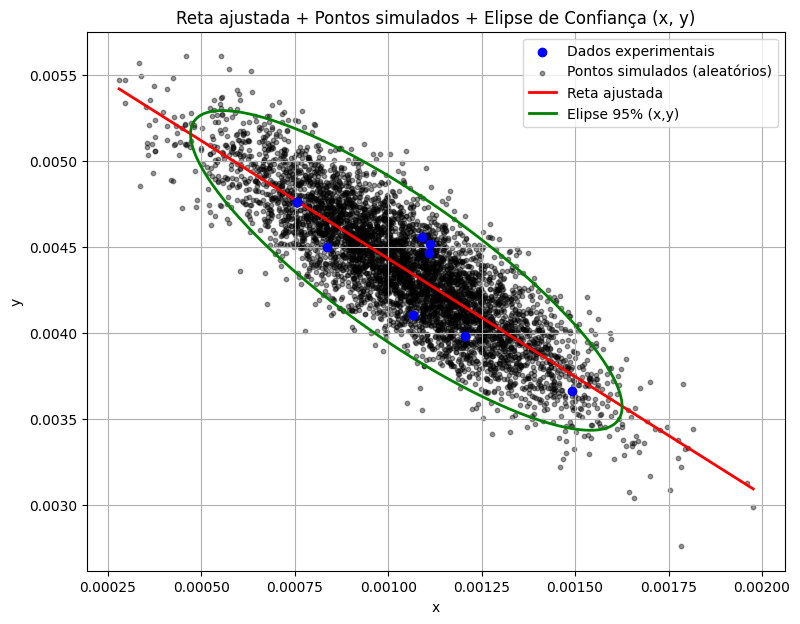

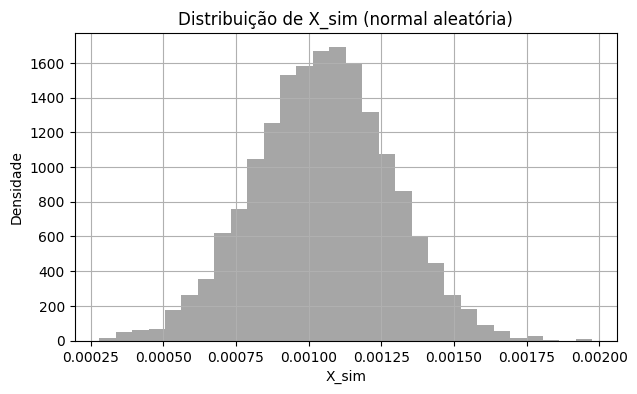

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.linalg import sqrtm
from io import StringIO

# =========================================================
# === 1. NOVOS DADOS EXPERIMENTAIS ========================
# =========================================================
dados_brutos = """
0.000755 0.00475887325
0.000837 0.004501185796
0.001206 0.003983826852
0.001109 0.004464681111
0.001492 0.003660199986
0.001067 0.004101322263
0.00109 0.004558266353
0.000755 0.00475887325
0.001113 0.004513839603
"""

# =========================================================
# === 2. LÊ OS DADOS ======================================
# =========================================================
dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])
X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()
n = len(X)

# =========================================================
# === 3. AJUSTE LINEAR ====================================
# =========================================================
A = np.vstack([np.ones_like(X), X]).T
beta_hat = np.linalg.lstsq(A, Y, rcond=None)[0]
b_est, a_est = beta_hat
Y_pred = a_est * X + b_est

# resíduos e variância
resid = Y - Y_pred
sigma2_hat = np.var(resid, ddof=2)
sigma_hat = np.sqrt(sigma2_hat)

print("=== RESULTADOS DO AJUSTE ===")
print(f"Coeficiente angular (a): {a_est:.6f}")
print(f"Intercepto (b): {b_est:.6f}")
print(f"Desvio padrão residual: {sigma_hat:.6f}")

# =========================================================
# === 4. GERA NOVOS PONTOS A PARTIR DO MODELO (ALEATÓRIO) =
# =========================================================
np.random.seed(42)
n_sintetico = 5000

# Geração aleatória de X com distribuição normal baseada nos dados experimentais
media_x = np.mean(X)
desvio_x = np.std(X, ddof=1)
X_sim = np.random.normal(media_x, desvio_x, n_sintetico)

# Y gerado conforme o modelo linear + ruído experimental
Y_sim = a_est * X_sim + b_est + np.random.normal(0, sigma_hat, n_sintetico)

# =========================================================
# === 5. COVARIÂNCIA E ELIPSE NO ESPAÇO (x, y) ============
# =========================================================
mean_x, mean_y = np.mean(X_sim), np.mean(Y_sim)
cov_xy = np.cov(X_sim, Y_sim)
corr_xy = np.corrcoef(X_sim, Y_sim)[0, 1]

print("\n=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===")
print(f"Média x: {mean_x:.6f}")
print(f"Média y: {mean_y:.6f}")
print(f"Correlação x–y: {corr_xy:.6f}")

# elipse 80%
r = np.sqrt(chi2.isf(1 - 0.95, df=2))
T = np.linspace(0, 2 * np.pi, 400)
circle = r * np.vstack([np.cos(T), np.sin(T)])
transform = sqrtm(cov_xy)
ellipse_points = transform @ circle
x_el = ellipse_points[0, :] + mean_x
y_el = ellipse_points[1, :] + mean_y

# =========================================================
# === 6. GRÁFICO FINAL ====================================
# =========================================================
plt.figure(figsize=(9, 7))
plt.scatter(X, Y, color='blue', label='Dados experimentais', zorder=3)
plt.scatter(X_sim, Y_sim, color='black', s=10, alpha=0.4, label='Pontos simulados (aleatórios)', zorder=1)
plt.plot(np.sort(X_sim), a_est * np.sort(X_sim) + b_est, color='red', linewidth=2, label='Reta ajustada')
plt.plot(x_el, y_el, color='green', linewidth=2, label='Elipse 95% (x,y)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Reta ajustada + Pontos simulados + Elipse de Confiança (x, y)')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 7. HISTOGRAMA DE X SIMULADO =========================
# =========================================================
plt.figure(figsize=(7, 4))
plt.hist(X_sim, bins=30, density=True, color='gray', alpha=0.7)
plt.title('Distribuição de X_sim (normal aleatória)')
plt.xlabel('X_sim')
plt.ylabel('Densidade')
plt.grid(True)
plt.show()


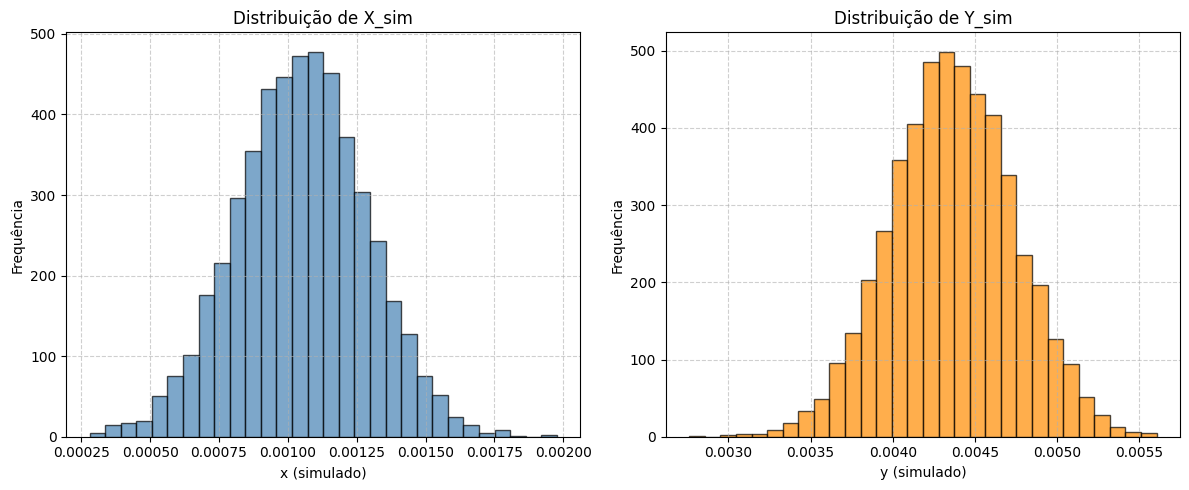

In [ ]:
# =========================================================
# === 7. HISTOGRAMAS SEPARADOS (APENAS SIMULADOS) ========
# =========================================================

plt.figure(figsize=(12, 5))

# --- Histograma de X_sim ---
plt.subplot(1, 2, 1)
plt.hist(X_sim, bins=30, color='steelblue', alpha=0.7, edgecolor='black')
plt.xlabel('x (simulado)')
plt.ylabel('Frequência')
plt.title('Distribuição de X_sim')
plt.grid(True, linestyle='--', alpha=0.6)

# --- Histograma de Y_sim ---
plt.subplot(1, 2, 2)
plt.hist(Y_sim, bins=30, color='darkorange', alpha=0.7, edgecolor='black')
plt.xlabel('y (simulado)')
plt.ylabel('Frequência')
plt.title('Distribuição de Y_sim')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


Matriz de correlação:

            kd        kW      kinv
kd    1.000000  0.755504 -0.844064
kW    0.755504  1.000000 -0.478294
kinv -0.844064 -0.478294  1.000000


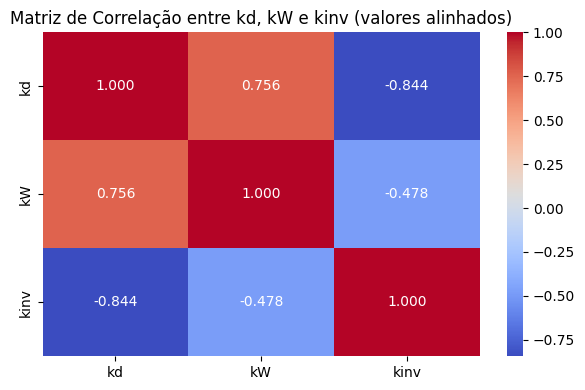

In [ ]:
import pandas as pd
import io
import matplotlib.pyplot as plt
import seaborn as sns

# === DADOS BRUTOS ===
dados1 = """
0.000755 0.905
0.000837 0.864
0.001206 1
0.000883 1.312
0.001109 1
0.001492 1
0.004421 4.228
0.004849 3.385
0.000585 0
0.001067 1
0.001090 1
0.000755 0.905
0.001113 1
0.003406 3.098
"""

dados2 = """
0.000755 0.00475887325
0.000837 0.004501185796
0.001206 0.003983826852
0.001109 0.004464681111
0.001492 0.003660199986
0.001067 0.004101322263
0.00109 0.004558266353
0.000755 0.00475887325
0.001113 0.00451383960
"""

# === CRIAÇÃO DOS DATAFRAMES ===
df1 = pd.read_csv(io.StringIO(dados1), sep=" ", header=None, names=["kd", "kW"])
df2 = pd.read_csv(io.StringIO(dados2), sep=" ", header=None, names=["kd", "kinv"])

# === REMOVER DUPLICATAS E ALINHAR PELA COLUNA COMUM ===
# Remover duplicatas com base na coluna kd
df1 = df1.drop_duplicates(subset="kd").reset_index(drop=True)
df2 = df2.drop_duplicates(subset="kd").reset_index(drop=True)

# Fazer o merge apenas nas linhas que têm o mesmo kd em ambos
df = pd.merge(df1, df2, on="kd", how="inner")

# === MATRIZ DE CORRELAÇÃO ===
corr = df.corr()

print("Matriz de correlação:\n")
print(corr)

# === HEATMAP (visualização gráfica) ===
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Matriz de Correlação entre kd, kW e kinv (valores alinhados)")
plt.tight_layout()
plt.show()


# Chin 2015

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from sklearn.metrics import r2_score

# === 1. Colocar os dados diretamente ===
dados_brutos = """
0.000755 0.905
0.000837 0.864
0.000684 0.733
0.001206 1
0.000883 1.312
0.001109 1
0.001492 1
0.004421 4.228
0.004849 3.385
0.000585 0
0.001067 1
0.00109 1
0.002145 5.009
0.000755 0.905
0.001113 1
0.003406 3.098
"""  # coloque todos os pares aqui até o final

# Converte o texto em DataFrame
from io import StringIO
dados = pd.read_csv(StringIO(dados_brutos), sep=" ", header=None, names=["x", "y"])

# === 2. Define a função do modelo ===
def f_reta(x, par):
    b, a = par
    return a * x + b

# === 3. Função de resíduos ===
def f_res(par, f_modelo, X_var, Y_var, dados, its=0):
    n_exp = dados.shape[0]
    v_delta = np.empty(n_exp)
    v_y_pred = np.empty(n_exp)
    for k, row in dados.iterrows():
        y = row[Y_var].to_numpy()
        x = row[X_var].to_numpy()
        y_pred = f_modelo(x, par)
        v_y_pred[k] = float(y_pred[0])
        delta = y_pred - y
        v_delta[k] = float(delta[0])
    if its == 0:
        return v_delta
    elif its == 7:
        return v_y_pred

# === 4. Ajuste por mínimos quadrados ===
X_var = ['x']
Y_var = ['y']
par_inicial = [0.0, -1.0]

resp_estimacao = least_squares(f_res, par_inicial, args=(f_reta, X_var, Y_var, dados))
par_est = resp_estimacao.x
b_est, a_est = par_est

print(f"Parâmetros estimados: a = {a_est:.5f}, b = {b_est:.5f}")

# === 5. Avaliação ===
y_pred = f_res(par_est, f_reta, X_var, Y_var, dados, its=7)
R2 = r2_score(dados[Y_var].to_numpy(), y_pred)
print(f"R² = {R2:.5f}")

# === 6. Gráfico de Paridade ===
plt.figure(figsize=(8,6))
plt.plot(dados['y'], y_pred, 'bo', label='Predito vs Experimental')
plt.plot(dados['y'], dados['y'], 'r--', label='Referência 1:1')
plt.xlabel('y experimental')
plt.ylabel('y predito')
plt.title('Gráfico de Paridade')
plt.legend()
plt.grid()
plt.show()

# === 7. Gráfico de Ajuste Linear ===
plt.figure(figsize=(8,6))
plt.plot(dados['x'], dados['y'], 'bo', label='Dados experimentais')
plt.plot(dados['x'], f_reta(dados['x'], par_est), 'r-', label='Ajuste linear')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Ajuste Linear por Mínimos Quadrados')
plt.legend()
plt.grid()
plt.show()


ParserError: Error tokenizing data. C error: Expected 2 fields in line 17, saw 3


=== RESULTADOS DO AJUSTE ===
Coeficiente angular (a): 1452.596659
Intercepto (b): 0.358950
Desvio padrão residual: 1.496249

=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===
Média x: 0.000677
Média y: 1.327130
Correlação x–y: 0.415998


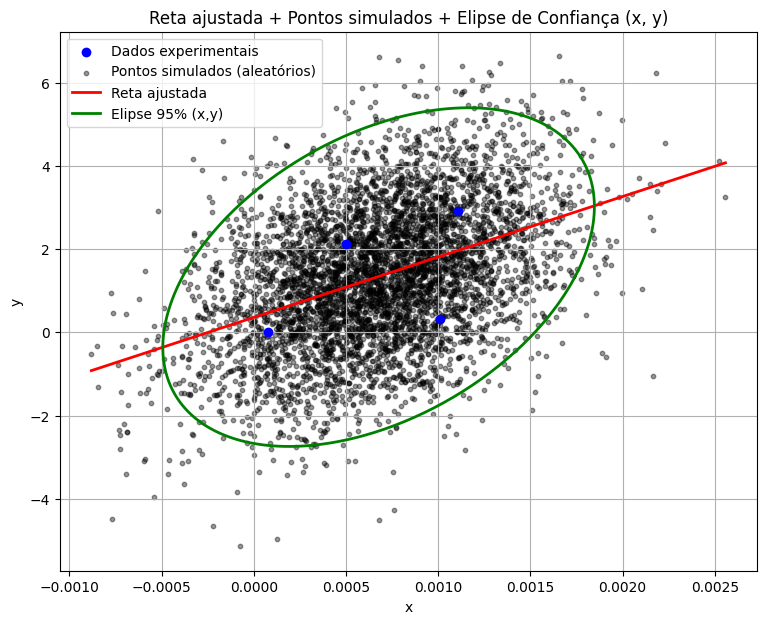

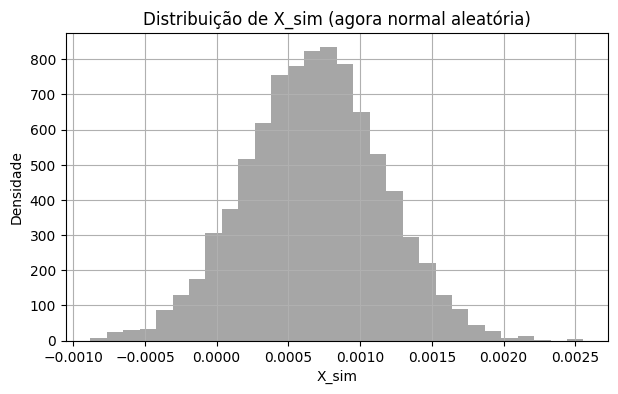

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.linalg import sqrtm
from io import StringIO

# =========================================================
# === 1. NOVOS DADOS EXPERIMENTAIS ========================
# =========================================================
dados_brutos = """
0.000075 0
0.000502 2.128
0.001011 0.314
0.001108 2.91
"""

# =========================================================
# === 2. LÊ OS DADOS ======================================
# =========================================================
dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])
X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()
n = len(X)

# =========================================================
# === 3. AJUSTE LINEAR ====================================
# =========================================================
A = np.vstack([np.ones_like(X), X]).T
beta_hat = np.linalg.lstsq(A, Y, rcond=None)[0]
b_est, a_est = beta_hat
Y_pred = a_est * X + b_est

# resíduos e variância
resid = Y - Y_pred
sigma2_hat = np.var(resid, ddof=2)
sigma_hat = np.sqrt(sigma2_hat)

print("=== RESULTADOS DO AJUSTE ===")
print(f"Coeficiente angular (a): {a_est:.6f}")
print(f"Intercepto (b): {b_est:.6f}")
print(f"Desvio padrão residual: {sigma_hat:.6f}")

# =========================================================
# === 4. GERA NOVOS PONTOS A PARTIR DO MODELO (ALEATÓRIO) =
# =========================================================
np.random.seed(42)
n_sintetico = 5000

# X_sim aleatório com distribuição normal baseada nos dados reais
media_x = np.mean(X)
desvio_x = np.std(X, ddof=1)
X_sim = np.random.normal(media_x, desvio_x, n_sintetico)

# Gera Y_sim conforme o modelo linear + ruído experimental
Y_sim = a_est * X_sim + b_est + np.random.normal(0, sigma_hat, n_sintetico)

# =========================================================
# === 5. COVARIÂNCIA E ELIPSE NO ESPAÇO (x, y) ============
# =========================================================
mean_x, mean_y = np.mean(X_sim), np.mean(Y_sim)
cov_xy = np.cov(X_sim, Y_sim)
corr_xy = np.corrcoef(X_sim, Y_sim)[0, 1]

print("\n=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===")
print(f"Média x: {mean_x:.6f}")
print(f"Média y: {mean_y:.6f}")
print(f"Correlação x–y: {corr_xy:.6f}")

# elipse 85%
r = np.sqrt(chi2.isf(1 - 0.95, df=2))
T = np.linspace(0, 2*np.pi, 400)
circle = r * np.vstack([np.cos(T), np.sin(T)])
transform = sqrtm(cov_xy)
ellipse_points = transform @ circle
x_el = ellipse_points[0, :] + mean_x
y_el = ellipse_points[1, :] + mean_y

# =========================================================
# === 6. GRÁFICO FINAL ====================================
# =========================================================
plt.figure(figsize=(9,7))
plt.scatter(X, Y, color='blue', label='Dados experimentais', zorder=3)
plt.scatter(X_sim, Y_sim, color='black', s=10, alpha=0.4, label='Pontos simulados (aleatórios)', zorder=1)
plt.plot(np.sort(X_sim), a_est * np.sort(X_sim) + b_est, color='red', linewidth=2, label='Reta ajustada')
plt.plot(x_el, y_el, color='green', linewidth=2, label='Elipse 95% (x,y)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Reta ajustada + Pontos simulados + Elipse de Confiança (x, y)')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 7. HISTOGRAMA PARA VERIFICAR X SIMULADO ============
# =========================================================
plt.figure(figsize=(7,4))
plt.hist(X_sim, bins=30, density=True, color='gray', alpha=0.7)
plt.title('Distribuição de X_sim (agora normal aleatória)')
plt.xlabel('X_sim')
plt.ylabel('Densidade')
plt.grid(True)
plt.show()


Pode se observar que ficou claramente para cima

=== RESULTADOS DO AJUSTE ===
Coeficiente angular (a): -0.058683
Intercepto (b): 0.000185
Desvio padrão residual: 0.000198

=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===
Média x: 0.000429
Média y: 0.000158
Correlação x–y: -0.103612


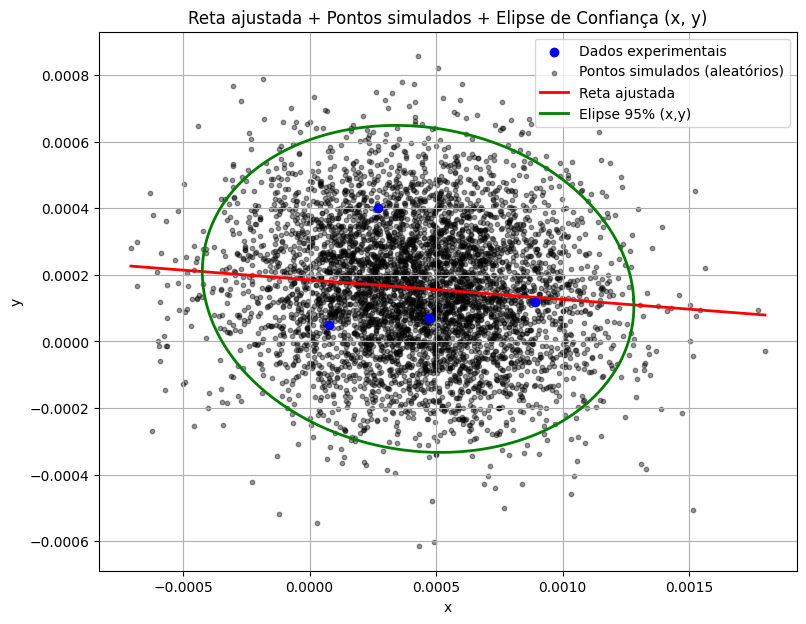

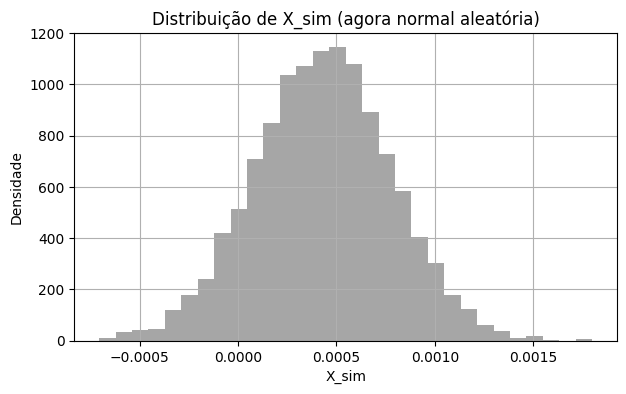

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.linalg import sqrtm
from io import StringIO

# =========================================================
# === 1. NOVOS DADOS EXPERIMENTAIS ========================
# =========================================================
dados_brutos = """
0.000075 0.00005
0.00027 0.0004
0.000892 0.00012
0.000471 0.00007
"""

# =========================================================
# === 2. LÊ OS DADOS ======================================
# =========================================================
dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])
X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()
n = len(X)

# =========================================================
# === 3. AJUSTE LINEAR ====================================
# =========================================================
A = np.vstack([np.ones_like(X), X]).T
beta_hat = np.linalg.lstsq(A, Y, rcond=None)[0]
b_est, a_est = beta_hat
Y_pred = a_est * X + b_est

# resíduos e variância
resid = Y - Y_pred
sigma2_hat = np.var(resid, ddof=2)
sigma_hat = np.sqrt(sigma2_hat)

print("=== RESULTADOS DO AJUSTE ===")
print(f"Coeficiente angular (a): {a_est:.6f}")
print(f"Intercepto (b): {b_est:.6f}")
print(f"Desvio padrão residual: {sigma_hat:.6f}")

# =========================================================
# === 4. GERA NOVOS PONTOS A PARTIR DO MODELO (ALEATÓRIO) =
# =========================================================
np.random.seed(42)
n_sintetico = 5000

# X_sim aleatório com distribuição normal baseada nos dados reais
media_x = np.mean(X)
desvio_x = np.std(X, ddof=1)
X_sim = np.random.normal(media_x, desvio_x, n_sintetico)

# Gera Y_sim conforme o modelo linear + ruído experimental
Y_sim = a_est * X_sim + b_est + np.random.normal(0, sigma_hat, n_sintetico)

# =========================================================
# === 5. COVARIÂNCIA E ELIPSE NO ESPAÇO (x, y) ============
# =========================================================
mean_x, mean_y = np.mean(X_sim), np.mean(Y_sim)
cov_xy = np.cov(X_sim, Y_sim)
corr_xy = np.corrcoef(X_sim, Y_sim)[0, 1]

print("\n=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===")
print(f"Média x: {mean_x:.6f}")
print(f"Média y: {mean_y:.6f}")
print(f"Correlação x–y: {corr_xy:.6f}")

# elipse 85%
r = np.sqrt(chi2.isf(1 - 0.95, df=2))
T = np.linspace(0, 2*np.pi, 400)
circle = r * np.vstack([np.cos(T), np.sin(T)])
transform = sqrtm(cov_xy)
ellipse_points = transform @ circle
x_el = ellipse_points[0, :] + mean_x
y_el = ellipse_points[1, :] + mean_y

# =========================================================
# === 6. GRÁFICO FINAL ====================================
# =========================================================
plt.figure(figsize=(9,7))
plt.scatter(X, Y, color='blue', label='Dados experimentais', zorder=3)
plt.scatter(X_sim, Y_sim, color='black', s=10, alpha=0.4, label='Pontos simulados (aleatórios)', zorder=1)
plt.plot(np.sort(X_sim), a_est * np.sort(X_sim) + b_est, color='red', linewidth=2, label='Reta ajustada')
plt.plot(x_el, y_el, color='green', linewidth=2, label='Elipse 95% (x,y)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Reta ajustada + Pontos simulados + Elipse de Confiança (x, y)')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 7. HISTOGRAMA PARA VERIFICAR X SIMULADO ============
# =========================================================
plt.figure(figsize=(7,4))
plt.hist(X_sim, bins=30, density=True, color='gray', alpha=0.7)
plt.title('Distribuição de X_sim (agora normal aleatória)')
plt.xlabel('X_sim')
plt.ylabel('Densidade')
plt.grid(True)
plt.show()


# Hykkerud

=== RESULTADOS DO AJUSTE ===
Coeficiente angular (a): -52.766335
Intercepto (b): 0.045417
Desvio padrão residual: 0.047292

=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===
Média x: 0.000430
Média y: 0.022245
Correlação x–y: -0.352012


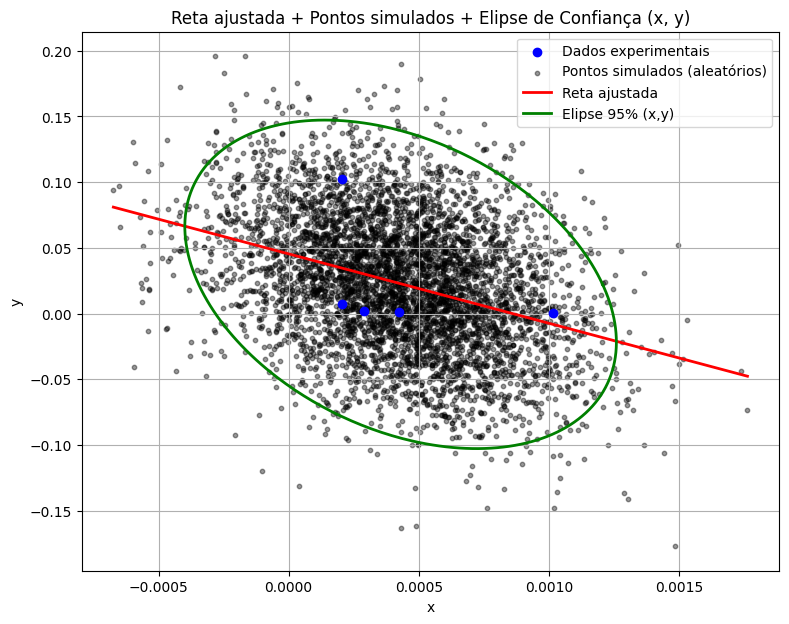

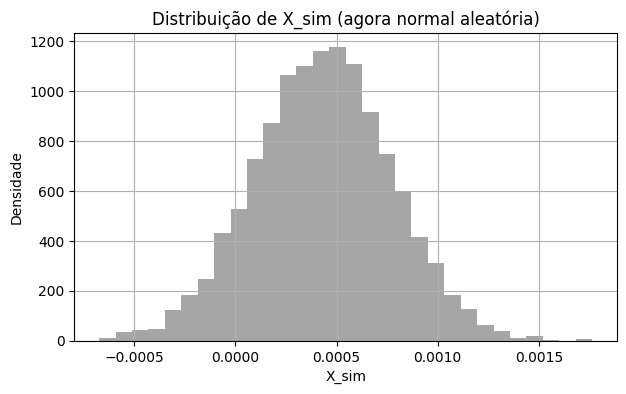

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.linalg import sqrtm
from io import StringIO

# =========================================================
# === 1. NOVOS DADOS EXPERIMENTAIS ========================
# =========================================================
dados_brutos = """
0.000206 0.10268
0.000204 0.007
0.000291 0.00231
0.000426 0.001546
0.001015 0.00052440
"""

# =========================================================
# === 2. LÊ OS DADOS ======================================
# =========================================================
dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])
X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()
n = len(X)

# =========================================================
# === 3. AJUSTE LINEAR ====================================
# =========================================================
A = np.vstack([np.ones_like(X), X]).T
beta_hat = np.linalg.lstsq(A, Y, rcond=None)[0]
b_est, a_est = beta_hat
Y_pred = a_est * X + b_est

# resíduos e variância
resid = Y - Y_pred
sigma2_hat = np.var(resid, ddof=2)
sigma_hat = np.sqrt(sigma2_hat)

print("=== RESULTADOS DO AJUSTE ===")
print(f"Coeficiente angular (a): {a_est:.6f}")
print(f"Intercepto (b): {b_est:.6f}")
print(f"Desvio padrão residual: {sigma_hat:.6f}")

# =========================================================
# === 4. GERA NOVOS PONTOS A PARTIR DO MODELO (ALEATÓRIO) =
# =========================================================
np.random.seed(42)
n_sintetico = 5000

# X_sim aleatório com distribuição normal baseada nos dados reais
media_x = np.mean(X)
desvio_x = np.std(X, ddof=1)
X_sim = np.random.normal(media_x, desvio_x, n_sintetico)

# Gera Y_sim conforme o modelo linear + ruído experimental
Y_sim = a_est * X_sim + b_est + np.random.normal(0, sigma_hat, n_sintetico)

# =========================================================
# === 5. COVARIÂNCIA E ELIPSE NO ESPAÇO (x, y) ============
# =========================================================
mean_x, mean_y = np.mean(X_sim), np.mean(Y_sim)
cov_xy = np.cov(X_sim, Y_sim)
corr_xy = np.corrcoef(X_sim, Y_sim)[0, 1]

print("\n=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===")
print(f"Média x: {mean_x:.6f}")
print(f"Média y: {mean_y:.6f}")
print(f"Correlação x–y: {corr_xy:.6f}")

# elipse 85%
r = np.sqrt(chi2.isf(1 - 0.95, df=2))
T = np.linspace(0, 2*np.pi, 400)
circle = r * np.vstack([np.cos(T), np.sin(T)])
transform = sqrtm(cov_xy)
ellipse_points = transform @ circle
x_el = ellipse_points[0, :] + mean_x
y_el = ellipse_points[1, :] + mean_y

# =========================================================
# === 6. GRÁFICO FINAL ====================================
# =========================================================
plt.figure(figsize=(9,7))
plt.scatter(X, Y, color='blue', label='Dados experimentais', zorder=3)
plt.scatter(X_sim, Y_sim, color='black', s=10, alpha=0.4, label='Pontos simulados (aleatórios)', zorder=1)
plt.plot(np.sort(X_sim), a_est * np.sort(X_sim) + b_est, color='red', linewidth=2, label='Reta ajustada')
plt.plot(x_el, y_el, color='green', linewidth=2, label='Elipse 95% (x,y)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Reta ajustada + Pontos simulados + Elipse de Confiança (x, y)')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 7. HISTOGRAMA PARA VERIFICAR X SIMULADO ============
# =========================================================
plt.figure(figsize=(7,4))
plt.hist(X_sim, bins=30, density=True, color='gray', alpha=0.7)
plt.title('Distribuição de X_sim (agora normal aleatória)')
plt.xlabel('X_sim')
plt.ylabel('Densidade')
plt.grid(True)
plt.show()


=== RESULTADOS DO AJUSTE ===
Coeficiente angular (a): 669.585991
Intercepto (b): 0.466549
Desvio padrão residual: 0.565097

=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===
Média x: 0.000430
Média y: 0.749096
Correlação x–y: 0.367918


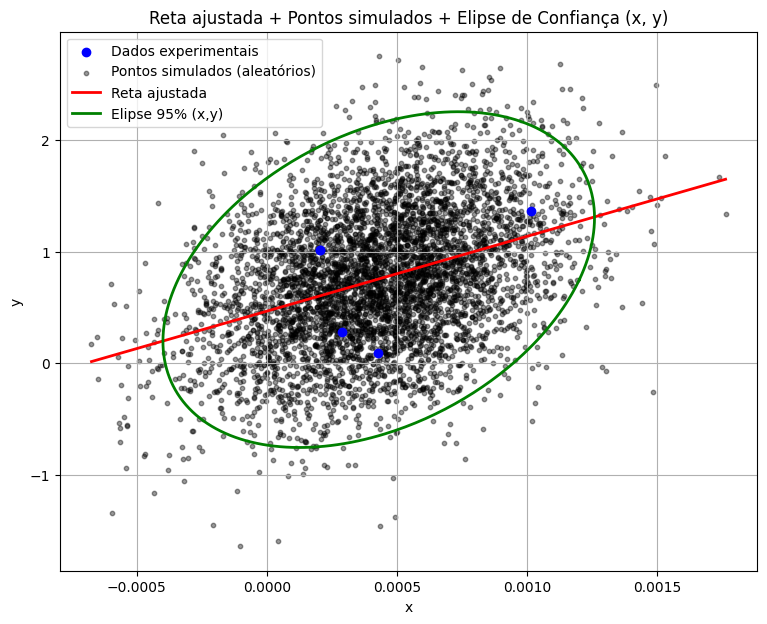

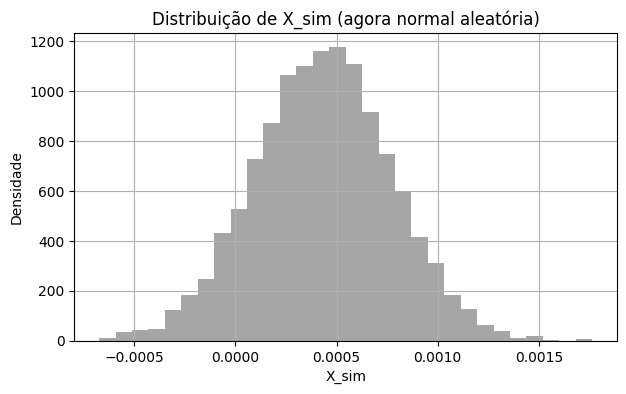

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.linalg import sqrtm
from io import StringIO

# =========================================================
# === 1. NOVOS DADOS EXPERIMENTAIS ========================
# =========================================================
dados_brutos = """
0.000206 1.01
0.000204 1.014
0.000291 0.284
0.000426 0.093
0.001015 1.366
"""

# =========================================================
# === 2. LÊ OS DADOS ======================================
# =========================================================
dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])
X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()
n = len(X)

# =========================================================
# === 3. AJUSTE LINEAR ====================================
# =========================================================
A = np.vstack([np.ones_like(X), X]).T
beta_hat = np.linalg.lstsq(A, Y, rcond=None)[0]
b_est, a_est = beta_hat
Y_pred = a_est * X + b_est

# resíduos e variância
resid = Y - Y_pred
sigma2_hat = np.var(resid, ddof=2)
sigma_hat = np.sqrt(sigma2_hat)

print("=== RESULTADOS DO AJUSTE ===")
print(f"Coeficiente angular (a): {a_est:.6f}")
print(f"Intercepto (b): {b_est:.6f}")
print(f"Desvio padrão residual: {sigma_hat:.6f}")

# =========================================================
# === 4. GERA NOVOS PONTOS A PARTIR DO MODELO (ALEATÓRIO) =
# =========================================================
np.random.seed(42)
n_sintetico = 5000

# X_sim aleatório com distribuição normal baseada nos dados reais
media_x = np.mean(X)
desvio_x = np.std(X, ddof=1)
X_sim = np.random.normal(media_x, desvio_x, n_sintetico)

# Gera Y_sim conforme o modelo linear + ruído experimental
Y_sim = a_est * X_sim + b_est + np.random.normal(0, sigma_hat, n_sintetico)

# =========================================================
# === 5. COVARIÂNCIA E ELIPSE NO ESPAÇO (x, y) ============
# =========================================================
mean_x, mean_y = np.mean(X_sim), np.mean(Y_sim)
cov_xy = np.cov(X_sim, Y_sim)
corr_xy = np.corrcoef(X_sim, Y_sim)[0, 1]

print("\n=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===")
print(f"Média x: {mean_x:.6f}")
print(f"Média y: {mean_y:.6f}")
print(f"Correlação x–y: {corr_xy:.6f}")

# elipse 85%
r = np.sqrt(chi2.isf(1 - 0.95, df=2))
T = np.linspace(0, 2*np.pi, 400)
circle = r * np.vstack([np.cos(T), np.sin(T)])
transform = sqrtm(cov_xy)
ellipse_points = transform @ circle
x_el = ellipse_points[0, :] + mean_x
y_el = ellipse_points[1, :] + mean_y

# =========================================================
# === 6. GRÁFICO FINAL ====================================
# =========================================================
plt.figure(figsize=(9,7))
plt.scatter(X, Y, color='blue', label='Dados experimentais', zorder=3)
plt.scatter(X_sim, Y_sim, color='black', s=10, alpha=0.4, label='Pontos simulados (aleatórios)', zorder=1)
plt.plot(np.sort(X_sim), a_est * np.sort(X_sim) + b_est, color='red', linewidth=2, label='Reta ajustada')
plt.plot(x_el, y_el, color='green', linewidth=2, label='Elipse 95% (x,y)')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Reta ajustada + Pontos simulados + Elipse de Confiança (x, y)')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 7. HISTOGRAMA PARA VERIFICAR X SIMULADO ============
# =========================================================
plt.figure(figsize=(7,4))
plt.hist(X_sim, bins=30, density=True, color='gray', alpha=0.7)
plt.title('Distribuição de X_sim (agora normal aleatória)')
plt.xlabel('X_sim')
plt.ylabel('Densidade')
plt.grid(True)
plt.show()


As trÊs literaturas Bhandere Chin Sharma

=== RESULTADOS DO AJUSTE ===
Coeficiente angular (a): -0.799914
Intercepto (b): 0.001018
Desvio padrão residual: 0.000268

=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===
Média x: 0.000626
Média y: 0.000514
Correlação x–y: -0.656341


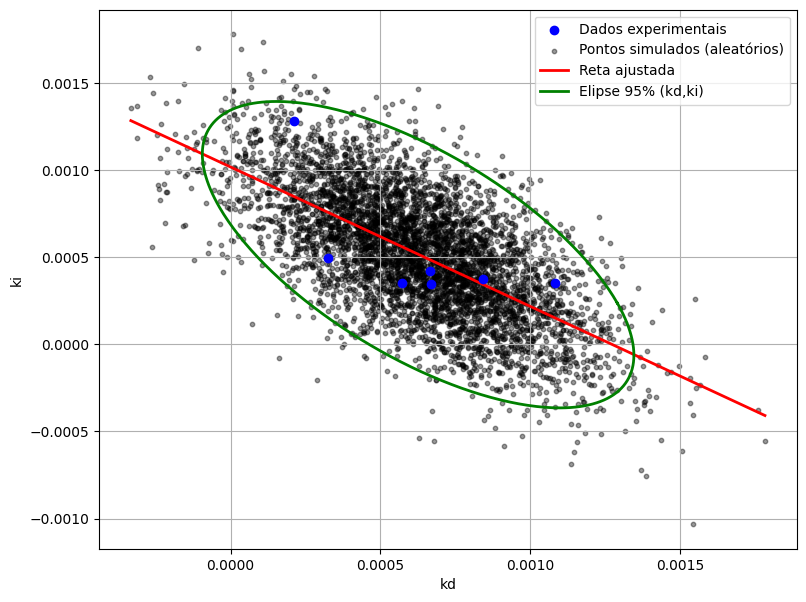

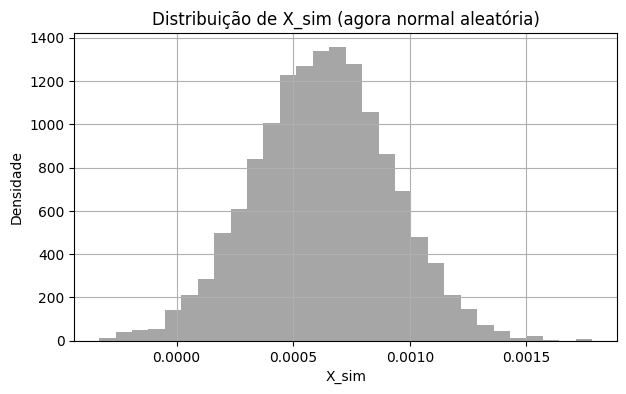

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.linalg import sqrtm
from io import StringIO

# =========================================================
# === 1. NOVOS DADOS EXPERIMENTAIS ========================
# =========================================================
dados_brutos = """
0.000667 0.00042
0.000573 0.0003537
0.000324 0.000498
0.000212 0.00128
0.000669 0.000348
0.000842 0.000377
0.001081 0.000352
"""

# =========================================================
# === 2. LÊ OS DADOS ======================================
# =========================================================
dados = pd.read_csv(StringIO(dados_brutos), sep=r"\s+", header=None, names=["x", "y"])
X = dados["x"].to_numpy()
Y = dados["y"].to_numpy()
n = len(X)

# =========================================================
# === 3. AJUSTE LINEAR ====================================
# =========================================================
A = np.vstack([np.ones_like(X), X]).T
beta_hat = np.linalg.lstsq(A, Y, rcond=None)[0]
b_est, a_est = beta_hat
Y_pred = a_est * X + b_est

# resíduos e variância
resid = Y - Y_pred
sigma2_hat = np.var(resid, ddof=2)
sigma_hat = np.sqrt(sigma2_hat)

print("=== RESULTADOS DO AJUSTE ===")
print(f"Coeficiente angular (a): {a_est:.6f}")
print(f"Intercepto (b): {b_est:.6f}")
print(f"Desvio padrão residual: {sigma_hat:.6f}")

# =========================================================
# === 4. GERA NOVOS PONTOS A PARTIR DO MODELO (ALEATÓRIO) =
# =========================================================
np.random.seed(42)
n_sintetico = 5000

# X_sim aleatório com distribuição normal baseada nos dados reais
media_x = np.mean(X)
desvio_x = np.std(X, ddof=1)
X_sim = np.random.normal(media_x, desvio_x, n_sintetico)

# Gera Y_sim conforme o modelo linear + ruído experimental
Y_sim = a_est * X_sim + b_est + np.random.normal(0, sigma_hat, n_sintetico)

# =========================================================
# === 5. COVARIÂNCIA E ELIPSE NO ESPAÇO (x, y) ============
# =========================================================
mean_x, mean_y = np.mean(X_sim), np.mean(Y_sim)
cov_xy = np.cov(X_sim, Y_sim)
corr_xy = np.corrcoef(X_sim, Y_sim)[0, 1]

print("\n=== CORRELAÇÃO DOS PONTOS SINTÉTICOS ===")
print(f"Média x: {mean_x:.6f}")
print(f"Média y: {mean_y:.6f}")
print(f"Correlação x–y: {corr_xy:.6f}")

# elipse 85%
r = np.sqrt(chi2.isf(1 - 0.95, df=2))
T = np.linspace(0, 2*np.pi, 400)
circle = r * np.vstack([np.cos(T), np.sin(T)])
transform = sqrtm(cov_xy)
ellipse_points = transform @ circle
x_el = ellipse_points[0, :] + mean_x
y_el = ellipse_points[1, :] + mean_y

# =========================================================
# === 6. GRÁFICO FINAL ====================================
# =========================================================
plt.figure(figsize=(9,7))
plt.scatter(X, Y, color='blue', label='Dados experimentais', zorder=3)
plt.scatter(X_sim, Y_sim, color='black', s=10, alpha=0.4, label='Pontos simulados (aleatórios)', zorder=1)
plt.plot(np.sort(X_sim), a_est * np.sort(X_sim) + b_est, color='red', linewidth=2, label='Reta ajustada')
plt.plot(x_el, y_el, color='green', linewidth=2, label='Elipse 95% (kd,ki)')
plt.xlabel('kd')
plt.ylabel('ki')
#plt.title('Reta ajustada + Pontos simulados + Elipse de Confiança (x, y)')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 7. HISTOGRAMA PARA VERIFICAR X SIMULADO ============
# =========================================================
plt.figure(figsize=(7,4))
plt.hist(X_sim, bins=30, density=True, color='gray', alpha=0.7)
plt.title('Distribuição de X_sim (agora normal aleatória)')
plt.xlabel('X_sim')
plt.ylabel('Densidade')
plt.grid(True)
plt.show()


=== LINEAR FIT RESULTS ===
Slope (a): -0.799914
Intercept (b): 0.001018
Residual standard deviation: 0.000268

=== SYNTHETIC POINTS STATISTICS ===
Mean x: 0.000626
Mean y: 0.000514
x–y correlation: -0.656341


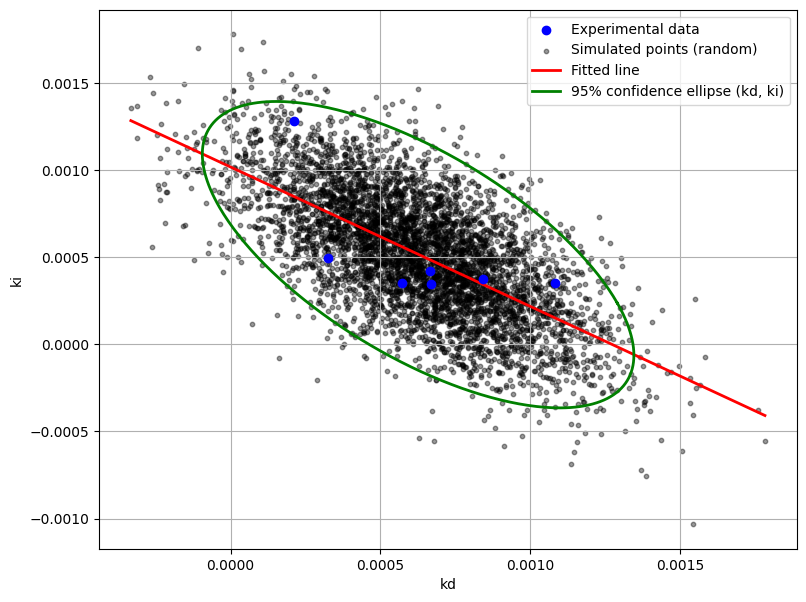

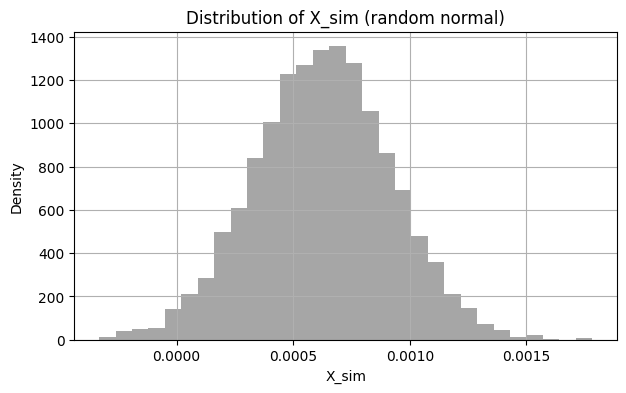

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.linalg import sqrtm
from io import StringIO

# =========================================================
# === 1. NEW EXPERIMENTAL DATA ===========================
# =========================================================
raw_data = """
0.000667 0.00042
0.000573 0.0003537
0.000324 0.000498
0.000212 0.00128
0.000669 0.000348
0.000842 0.000377
0.001081 0.000352
"""

# =========================================================
# === 2. READ THE DATA ===================================
# =========================================================
data = pd.read_csv(StringIO(raw_data), sep=r"\s+", header=None, names=["x", "y"])
X = data["x"].to_numpy()
Y = data["y"].to_numpy()
n = len(X)

# =========================================================
# === 3. LINEAR FIT ======================================
# =========================================================
A = np.vstack([np.ones_like(X), X]).T
beta_hat = np.linalg.lstsq(A, Y, rcond=None)[0]
b_est, a_est = beta_hat
Y_pred = a_est * X + b_est

# residuals and variance
resid = Y - Y_pred
sigma2_hat = np.var(resid, ddof=2)
sigma_hat = np.sqrt(sigma2_hat)

print("=== LINEAR FIT RESULTS ===")
print(f"Slope (a): {a_est:.6f}")
print(f"Intercept (b): {b_est:.6f}")
print(f"Residual standard deviation: {sigma_hat:.6f}")

# =========================================================
# === 4. GENERATE NEW POINTS FROM THE MODEL (RANDOM) =====
# =========================================================
np.random.seed(42)
n_synthetic = 5000

# Random X_sim based on the real data
mean_x = np.mean(X)
std_x = np.std(X, ddof=1)
X_sim = np.random.normal(mean_x, std_x, n_synthetic)

# Y_sim generated according to the linear model + experimental noise
Y_sim = a_est * X_sim + b_est + np.random.normal(0, sigma_hat, n_synthetic)

# =========================================================
# === 5. COVARIANCE AND ELLIPSE IN (x, y) SPACE =========
# =========================================================
mean_x, mean_y = np.mean(X_sim), np.mean(Y_sim)
cov_xy = np.cov(X_sim, Y_sim)
corr_xy = np.corrcoef(X_sim, Y_sim)[0, 1]

print("\n=== SYNTHETIC POINTS STATISTICS ===")
print(f"Mean x: {mean_x:.6f}")
print(f"Mean y: {mean_y:.6f}")
print(f"x–y correlation: {corr_xy:.6f}")

# 95% confidence ellipse
r = np.sqrt(chi2.isf(1 - 0.95, df=2))
T = np.linspace(0, 2*np.pi, 400)
circle = r * np.vstack([np.cos(T), np.sin(T)])
transform = sqrtm(cov_xy)
ellipse_points = transform @ circle
x_ellipse = ellipse_points[0, :] + mean_x
y_ellipse = ellipse_points[1, :] + mean_y

# =========================================================
# === 6. FINAL PLOT ======================================
# =========================================================
plt.figure(figsize=(9,7))
plt.scatter(X, Y, color='blue', label='Experimental data', zorder=3)
plt.scatter(X_sim, Y_sim, color='black', s=10, alpha=0.4, label='Simulated points (random)', zorder=1)
plt.plot(np.sort(X_sim), a_est * np.sort(X_sim) + b_est, color='red', linewidth=2, label='Fitted line')
plt.plot(x_ellipse, y_ellipse, color='green', linewidth=2, label='95% confidence ellipse (kd, ki)')
plt.xlabel('kd')
plt.ylabel('ki')
#plt.title('Fitted line + Simulated points + Confidence ellipse (x, y)')
plt.legend()
plt.grid(True)
plt.show()

# =========================================================
# === 7. HISTOGRAM TO CHECK SIMULATED X ==================
# =========================================================
plt.figure(figsize=(7,4))
plt.hist(X_sim, bins=30, density=True, color='gray', alpha=0.7)
plt.title('Distribution of X_sim (random normal)')
plt.xlabel('X_sim')
plt.ylabel('Density')
plt.grid(True)
plt.show()


MAIS UMA REFERENCIA